# HW2: Multiple Object Video Detection (UCU AI 2026)
Everything in one Kaggle notebook: data, evaluation protocol, four detector families, analysis.

| Part | Content | Rubric item |
|---|---|---|
| A | EDA, ignored regions, sequence split, frame step, checks | Data understanding (1.0) |
| B | one COCO evaluation protocol for all models | all |
| C | models: Faster R-CNN, RetinaNet, YOLO11, RT-DETR + variants | four detector items |
| D | submission file (`image_id, PredictionString`) and its format check | Kaggle |
| E | run loop: train, evaluate, save | all |
| F | results table, curves, error analysis, density analysis | analysis parts |

**How to run** (notebook v10; the first output line must start with `notebook v10`, otherwise an older version is running)
1. Notebook settings: GPU on, Internet on, competition data added.
2. Optional pipeline test: `SMOKE = True` and a few names in `RUN`. It trains 1 epoch on a few frames and only checks that the code works (files get the prefix `smoke_`).
3. Real run: `SMOKE = False`, put 1-3 variants into `RUN` (one GPU session is 12 h max). Use **Save Version -> Save & Run All (Commit)**, so that the results stay in the notebook Output.
4. The run writes `submission.csv` for the model in `SUBMIT_FOR` and checks its format automatically. Download it from the Output tab (or use Submit) and write the run name in the submission comment.
5. At the end of the run loop `results_<runs>.zip` is created in the Output: download it (plus the logs) after each session.
6. If a run crashed after training (e.g. out of memory while predicting), the weights are in the Output of that version: add it as input, put its path into `PRIOR_OUTPUTS` and the model is not retrained (`REUSE_TRAINED = True`).
7. Copy the printed `RESULT` lines into your notes. The next session starts from an empty `/kaggle/working`: add the previous version as input and put its path into `PRIOR_OUTPUTS`.


## 0. Config
Change only this cell.

In [1]:
from pathlib import Path
import os, sys, json, csv, time, random, shutil, gc, math, pickle, io, contextlib
from collections import defaultdict, Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image
from tqdm.auto import tqdm

# ---- what to do in this session (variant names are in C1) ----
RUN = []
SUBMIT_FOR = []   # write submission.csv for these runs (put the final model here later)
SMOKE = False                # True = tiny pipeline test, False = real run
EPOCHS = 10                  # same epoch budget for every model
REUSE_TRAINED = True         # True = if runs/<name>/weights/best.pt exists (e.g. copied from PRIOR_OUTPUTS), skip training and only predict
RUN_EDA = True               # False after the first run (saves time)
PRIOR_OUTPUTS = []           # outputs of earlier sessions (Add Input -> Notebook output), e.g. ["/kaggle/input/hw2-run1"]; see Part F

# ---- data protocol (fixed for all models) ----
STEP_TRAIN, STEP_VAL = 4, 4  # keep every 4th frame (see 2.5)
MASK_IGNORED = True          # paint ignored regions grey in train images
MAX_DET = 300                # max detections per image (max objects per frame in train is 180)
SEED = 42

# data experiments (same model and 640 px as yolo_base, only the training data changes); run one of them alone in a session
DATA_VARIANTS = {"yolo_step2": {"STEP_TRAIN": 2},         # every 2nd frame instead of every 4th: twice as many training frames
                 "yolo_nomask": {"MASK_IGNORED": False}}  # ignored regions are NOT painted grey
_dv = [n for n in RUN if n in DATA_VARIANTS]
assert len(_dv) == 0 or RUN == _dv[:1], "a data variant changes the training subset: put it alone into RUN"
if _dv:
    globals().update(DATA_VARIANTS[_dv[0]])
    print("data variant:", _dv[0], DATA_VARIANTS[_dv[0]])

# ---- training ----
IMGSZ_TV = 640               # torchvision models: long side of the input
TV_BATCH = 8
CLOSE_MOSAIC = 2             # ultralytics: mosaic is switched off for the last 2 epochs only
CACHE = "ram"
WORKERS = 4
ALLOW_CPU = True

TAG = "smoke_" if SMOKE else ""   # smoke files never mix with real results
if SMOKE:
    EPOCHS, N_TRAIN_CAP, N_VAL_CAP, SUB_LIMIT, FRACTION = 1, 160, 60, 20, 0.03
else:
    N_TRAIN_CAP = N_VAL_CAP = SUB_LIMIT = None   # SUB_LIMIT = None: submission covers all 3811 test frames
    FRACTION = 1.0

ROOT = Path("/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026")
if not ROOT.exists():
    ROOT = Path("/kaggle/input/multiple-object-video-detection-hw-2-ucu-ai-2026")
WORK = Path("/kaggle/working")           # saved as notebook output
OUT = Path("/kaggle/temp/hw2_sub")       # big temporary files (resized subset)
OUT.mkdir(parents=True, exist_ok=True)

os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")   # less GPU memory fragmentation
import torch
HAS_GPU = torch.cuda.is_available()
assert HAS_GPU or ALLOW_CPU, "turn on the GPU"
DEVICE = 0 if HAS_GPU else "cpu"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("notebook v10 | ROOT:", ROOT, "\nGPU:", HAS_GPU, "| smoke:", SMOKE, "| epochs:", EPOCHS, "| run:", RUN, "| reuse weights:", REUSE_TRAINED)
# result zips of earlier sessions (metrics, detections, curves) are unpacked into the working folder
import zipfile
for d in map(Path, PRIOR_OUTPUTS):
    for z in d.glob("results_*.zip"):
        zipfile.ZipFile(z).extractall(WORK); print("unpacked:", z.name)

# weights of earlier sessions (Ultralytics models): copy best.pt into /kaggle/working/runs so that training can be skipped
for d in map(Path, PRIOR_OUTPUTS):
    for f in d.glob("runs/*/weights/best.pt"):
        t_ = WORK / f.relative_to(d)
        if not t_.exists():
            t_.parent.mkdir(parents=True, exist_ok=True); shutil.copy2(f, t_); print("copied weights:", t_)

import glob
PRIOR_OUTPUTS = sorted({os.path.dirname(f) for f in
                        glob.glob("/kaggle/input/*/metrics_*.json") +
                        glob.glob("/kaggle/input/*/*/metrics_*.json") +
                        glob.glob("/kaggle/input/*/*/*/metrics_*.json")})
print("PRIOR_OUTPUTS:", PRIOR_OUTPUTS)

notebook v10 | ROOT: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026 
GPU: False | smoke: False | epochs: 10 | run: [] | reuse weights: True
PRIOR_OUTPUTS: ['/kaggle/input/datasets/bohdanazubrytska/results-hw2']


In [2]:
!pip install -q ultralytics     # needs Internet = On

# Part A. Data
The organisers give COCO annotations, YOLO labels and ignored regions (`iscrowd=1`).
Plan: EDA -> decisions -> sequence-level split (already given: train and val are different videos) -> subsample frames -> mask ignored regions -> check.

In [3]:
READY = False
info_f = OUT / "subset_info.json"
if info_f.exists():
    old = json.loads(info_f.read_text())
    READY = (old.get("step_train"), old.get("step_val"), old.get("mask_ignored")) == (STEP_TRAIN, STEP_VAL, MASK_IGNORED) \
            and (OUT / "val_sub.json").exists()
NEED_DATA = RUN_EDA or not READY
cmap = plt.get_cmap("tab10")

def yolo_label_path(split, file_name):
    return ROOT / split / "labels" / Path(file_name).relative_to("images").with_suffix(".txt")

print("subset ready:", READY, "| load annotations:", NEED_DATA)

subset ready: False | load annotations: True


## A1. What is in the data folder

In [4]:
if RUN_EDA:
    print("root :", sorted(p.name for p in ROOT.iterdir()))
    for s in ["train", "val", "test"]:
        print(f"{s:5s}:", sorted(p.name for p in (ROOT / s).iterdir()))
    print()
    print((ROOT / "train" / "data.yaml").read_text())

root : ['test', 'test_images.csv', 'train', 'val']
train: ['annotations_coco.json', 'data.yaml', 'ignore', 'images', 'labels']
val  : ['annotations_coco.json', 'data.yaml', 'ignore', 'images', 'labels']
test : ['images']

path: .
train: images
val: images
nc: 8
names: ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]



In [5]:
if NEED_DATA:
    # Load COCO annotations of train and val into DataFrames
    DATA = {}
    for split in ["train", "val"]:
        raw = json.loads((ROOT / split / "annotations_coco.json").read_text())
        imgs = pd.DataFrame(raw["images"])
        anns = pd.DataFrame(raw["annotations"])
        bb = np.array(anns["bbox"].tolist(), dtype=float)
        anns = anns.drop(columns="bbox").assign(x=bb[:, 0], y=bb[:, 1], w=bb[:, 2], h=bb[:, 3])
        DATA[split] = {"imgs": imgs, "anns": anns}
        if split == "train":
            META = {"info": raw.get("info", {}), "categories": raw["categories"]}
        del raw

    CATS = {c["id"]: c["name"] for c in META["categories"]}
    print("classes:", CATS)

    # the provided split must be disjoint by video (no leakage between train and val)
    assert not set(DATA["train"]["imgs"].video) & set(DATA["val"]["imgs"].video), "train and val share videos!"
    print("train and val are disjoint by video")

    def objects(split):
        """Real objects only (iscrowd == 0). iscrowd == 1 marks ignored regions."""
        a = DATA[split]["anns"]
        return a[a.iscrowd == 0]

    rows = []
    for s, d in DATA.items():
        a, im = d["anns"], d["imgs"]
        cr = a[a.iscrowd == 1]
        rows.append({"split": s, "videos": im.video_id.nunique(), "frames": len(im),
                     "objects": int((a.iscrowd == 0).sum()), "crowd_annotations": len(cr),
                     "unique_ignored_regions": len(cr[["image_id", "x", "y", "w", "h"]].drop_duplicates())})
    print(pd.DataFrame(rows).to_string(index=False))
    print("\nimage sizes (width, height):")
    for s, d in DATA.items():
        print(" ", s, dict(d["imgs"][["width", "height"]].value_counts().items()))
    print("\nHow original VisDrone classes were merged (rows: orig_category_id, columns: category_id):")
    print(DATA["train"]["anns"].groupby(["orig_category_id", "category_id"]).size().unstack(fill_value=0).to_string())

classes: {1: 'person', 2: 'bicycle', 3: 'car', 4: 'van', 5: 'truck', 6: 'tricycle', 7: 'bus', 8: 'motor'}
train and val are disjoint by video
split  videos  frames  objects  crowd_annotations  unique_ignored_regions
train      56   24201  1105516             510744                   63843
  val       7    2846   114132              31960                    3995

image sizes (width, height):
  train {(1904, 1071): 12895, (1344, 756): 5645, (2688, 1512): 3505, (1360, 765): 962, (1920, 1080): 721, (2720, 1530): 473}
  val {(3840, 2160): 978, (1344, 756): 827, (1904, 1071): 459, (2720, 1530): 349, (2688, 1512): 233}

How original VisDrone classes were merged (rows: orig_category_id, columns: category_id):
category_id            1      2       3      4      5      6      7       8
orig_category_id                                                           
0                  62369  62369   62369  62369  62369  62369  62369   62369
1                 234305      0       0      0      0      0 

## 2. EDA
Goal: facts that justify the later choices (input size, anchors, augmentation, frame step).

### 2.1 Classes

             train_objects  train_share  val_share
category_id                                       
car                 505301       0.4571     0.2788
person              328701       0.2973     0.4408
motor               102819       0.0930     0.1054
van                  46940       0.0425     0.0599
tricycle             41349       0.0374     0.0481
bicycle              40255       0.0364     0.0528
truck                30498       0.0276     0.0119
bus                   9653       0.0087     0.0023


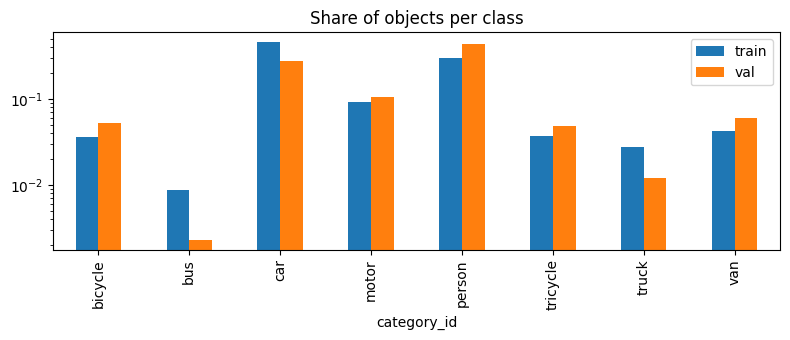

In [6]:
if RUN_EDA:
    share = pd.DataFrame({s: objects(s).category_id.map(CATS).value_counts(normalize=True) for s in DATA}).round(4)
    counts = objects("train").category_id.map(CATS).value_counts()
    print(pd.concat([counts.rename("train_objects"), share.add_suffix("_share")], axis=1).to_string())

    ax = share.plot.bar(figsize=(8, 3.5), title="Share of objects per class")
    ax.set_yscale("log"); plt.tight_layout(); plt.show()

### 2.2 Object sizes
COCO buckets by box area in pixels: small < 32², medium < 96², large above.

Share by COCO bucket:
        train    val
bucket              
medium  0.635  0.695
small   0.249  0.192
large   0.116  0.113

Share by bucket, per class (train):
bucket       small  medium  large
category_id                      
bicycle       0.24    0.74   0.01
bus           0.04    0.39   0.57
car           0.16    0.65   0.19
motor         0.30    0.68   0.01
person        0.39    0.60   0.00
tricycle      0.21    0.66   0.13
truck         0.09    0.58   0.33
van           0.21    0.63   0.16

sqrt(area) in px, percentiles 10/50/90: [24.0, 45.8, 101.6] | median box 44 x 48

Box size relative to frame width, percentiles 10/50/90: [0.0126, 0.0237, 0.0518]
Share of objects with sqrt(area) below 8 px after resizing each frame to width imgsz:
  imgsz 640: 9.8%
  imgsz 960: 1.7%
  imgsz 1280: 0.6%
  imgsz 1920: 0.0%


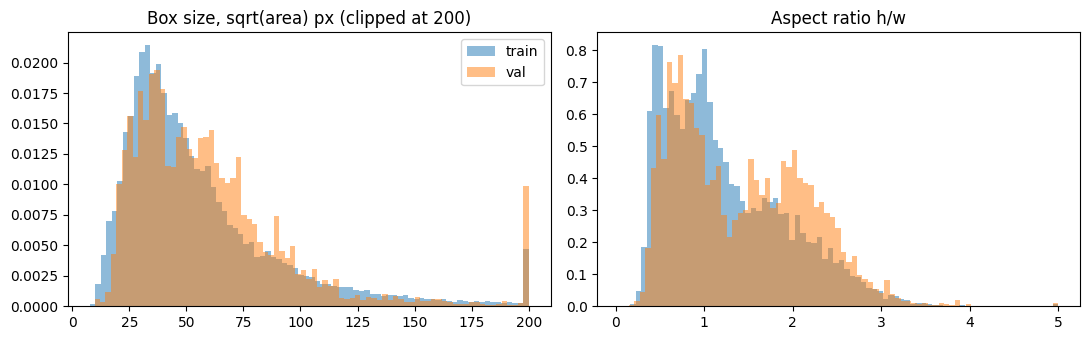

In [7]:
if RUN_EDA:
    BINS, LABELS = [0, 32 ** 2, 96 ** 2, np.inf], ["small", "medium", "large"]
    sizes = {}
    for s in DATA:
        o = objects(s).copy()
        o["sz"] = np.sqrt(o.w * o.h)
        o["bucket"] = pd.cut(o.w * o.h, BINS, labels=LABELS, right=False)
        sizes[s] = o

    print("Share by COCO bucket:")
    print(pd.DataFrame({s: sizes[s].bucket.value_counts(normalize=True) for s in sizes}).round(3).to_string())
    print("\nShare by bucket, per class (train):")
    print(sizes["train"].groupby(sizes["train"].category_id.map(CATS)).bucket.value_counts(normalize=True).unstack().round(2).to_string())

    o = sizes["train"]
    print("\nsqrt(area) in px, percentiles 10/50/90:", o.sz.quantile([.1, .5, .9]).round(1).tolist(),
          "| median box %.0f x %.0f" % (o.w.median(), o.h.median()))

    frame_w = DATA["train"]["imgs"].set_index("id").width
    rel = o.sz / o.image_id.map(frame_w)       # box size relative to the width of its own frame
    print("\nBox size relative to frame width, percentiles 10/50/90:", rel.quantile([.1, .5, .9]).round(4).tolist())
    print("Share of objects with sqrt(area) below 8 px after resizing each frame to width imgsz:")
    for imgsz in (640, 960, 1280, 1920):
        print(f"  imgsz {imgsz}: {(rel * imgsz < 8).mean():.1%}")

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    for s in sizes:
        ax[0].hist(sizes[s].sz.clip(upper=200), bins=80, alpha=.5, density=True, label=s)
        ax[1].hist((sizes[s].h / sizes[s].w.clip(lower=1)).clip(upper=5), bins=80, alpha=.5, density=True, label=s)
    ax[0].set_title("Box size, sqrt(area) px (clipped at 200)"); ax[1].set_title("Aspect ratio h/w"); ax[0].legend()
    plt.tight_layout(); plt.show()

### 2.3 Scene density and differences between videos

train: objects per frame mean=45.7 median=43 p95=118 p99=142 max=180 | empty frames: 0.0%
val: objects per frame mean=40.1 median=37 p95=103 p99=113 max=116 | empty frames: 0.0%


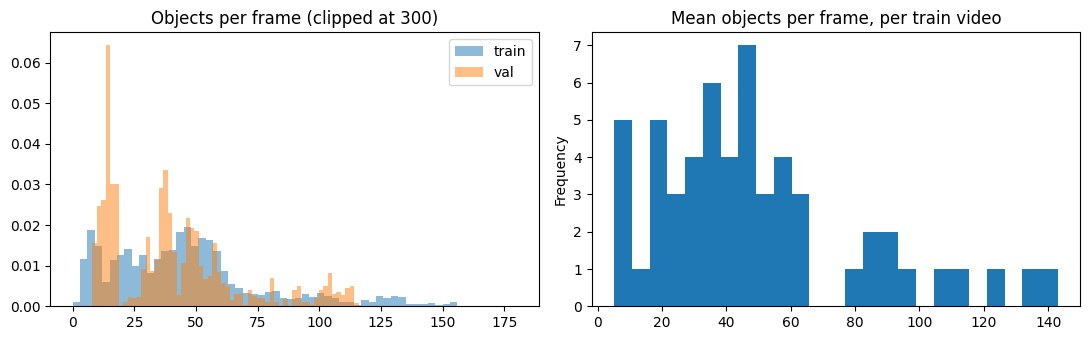


Sparsest and densest train videos:
                    frames  obj_per_frame  max_objs
uav0000218_00001_v     225            5.1         7
uav0000266_04830_v     116            6.1         7
uav0000266_03598_v     548            6.5        10
uav0000124_00944_v     398          124.6       134
uav0000126_00001_v     412          132.2       166
uav0000138_00000_v     213          143.0       156

Frames per train video: min=58 median=383 max=1424


In [8]:
if RUN_EDA:
    def frame_counts(split):
        d = DATA[split]
        return objects(split).groupby("image_id").size().reindex(d["imgs"].id, fill_value=0)

    fc = {s: frame_counts(s) for s in DATA}
    for s, c in fc.items():
        print(f"{s}: objects per frame mean={c.mean():.1f} median={c.median():.0f} p95={c.quantile(.95):.0f} "
              f"p99={c.quantile(.99):.0f} max={c.max()} | empty frames: {(c == 0).mean():.1%}")

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    for s, c in fc.items():
        ax[0].hist(c.clip(upper=300), bins=60, alpha=.5, density=True, label=s)
    ax[0].set_title("Objects per frame (clipped at 300)"); ax[0].legend()

    d = DATA["train"]
    vid = d["imgs"].set_index("id").video
    per_video = fc["train"].groupby(vid.reindex(fc["train"].index).values).agg(frames="count", obj_per_frame="mean", max_objs="max").round(1)
    per_video.obj_per_frame.plot.hist(bins=25, ax=ax[1], title="Mean objects per frame, per train video")
    plt.tight_layout(); plt.show()
    print("\nSparsest and densest train videos:")
    print(per_video.sort_values("obj_per_frame").iloc[[0, 1, 2, -3, -2, -1]].to_string())
    print("\nFrames per train video: min=%d median=%d max=%d" % (per_video.frames.min(), per_video.frames.median(), per_video.frames.max()))

### 2.4 Ignored regions

In [9]:
if RUN_EDA:
    for s, d in DATA.items():
        a, im = d["anns"], d["imgs"]
        cr = a[a.iscrowd == 1].drop_duplicates(["image_id", "x", "y", "w", "h"])
        n_reg = cr.groupby("image_id").size().reindex(im.id, fill_value=0)
        frame_area = im.set_index("id").eval("width * height")
        cover = ((cr.w * cr.h).groupby(cr.image_id).sum().reindex(im.id, fill_value=0) / frame_area).clip(upper=1)
        print(f"{s}: frames with ignored regions {(n_reg > 0).mean():.1%} | regions per frame (mean) {n_reg.mean():.1f} "
              f"| share of frame area covered (approx., mean) {cover.mean():.1%}")

train: frames with ignored regions 74.7% | regions per frame (mean) 2.6 | share of frame area covered (approx., mean) 2.4%
val: frames with ignored regions 50.4% | regions per frame (mean) 1.4 | share of frame area covered (approx., mean) 1.6%


### 2.5 Frame step
Consecutive frames are almost the same, so every k-th frame is enough. Check how far an object moves in k frames (in box sizes).

In [10]:
if RUN_EDA:
    im = DATA["train"]["imgs"].rename(columns={"id": "image_id"})[["image_id", "video_id", "frame_id"]]
    o = objects("train").merge(im, on="image_id")
    o["cx"], o["cy"], o["s"] = o.x + o.w / 2, o.y + o.h / 2, np.sqrt(o.w * o.h)
    base = o[["video_id", "track_id", "frame_id", "cx", "cy", "s"]]
    shift = {}
    for k in (1, 2, 4, 8, 16):
        nxt = base[["video_id", "track_id", "frame_id", "cx", "cy"]].copy()
        nxt["frame_id"] -= k
        m = base.merge(nxt, on=["video_id", "track_id", "frame_id"], suffixes=("", "_n"))
        shift[k] = (np.hypot(m.cx_n - m.cx, m.cy_n - m.cy) / m.s).median()
    print("Median shift of an object between frames t and t+k, in box sizes:")
    print(pd.Series(shift).round(3).rename_axis("k").to_string())
    del o, base

Median shift of an object between frames t and t+k, in box sizes:
k
1     0.044
2     0.085
4     0.168
8     0.334
16    0.656


### 2.6 Variation across videos
Per video: object size relative to frame width, share of small objects, class shares. Videos with different resolution are different scenes.

         objects     width  median_rel_size  small_share  car_share  \
count     56.000    56.000           56.000       56.000     56.000   
mean   19741.357  1967.714            0.026        0.209      0.415   
std    16073.296   459.474            0.007        0.172      0.251   
min      706.000  1344.000            0.014        0.000      0.000   
25%     8518.500  1904.000            0.022        0.095      0.242   
50%    16044.500  1904.000            0.025        0.184      0.455   
75%    25812.250  1908.000            0.030        0.283      0.605   
max    64916.000  2720.000            0.045        0.731      0.954   

       person_share  
count        56.000  
mean          0.354  
std           0.263  
min           0.000  
25%           0.161  
50%           0.271  
75%           0.484  
max           1.000  

by frame width:
       videos    rel  small    car
width                             
1344       11  0.028  0.371  0.242
1360        1  0.023  0.511  0.530
1904 

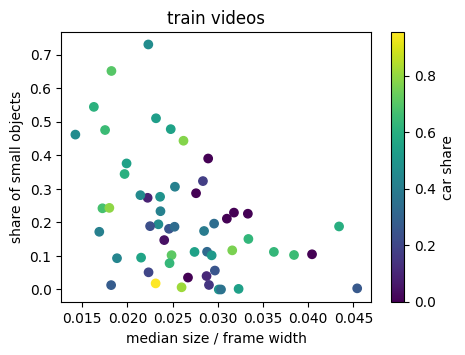

In [11]:
if RUN_EDA:
    o = objects("train").merge(
        DATA["train"]["imgs"][["id", "video", "width"]].rename(columns={"id": "image_id"}), on="image_id")
    o["rel"] = np.sqrt(o.w * o.h) / o.width
    o["small"] = (o.w * o.h < 32 ** 2)
    o["car"] = (o.category_id == 3)
    o["person"] = (o.category_id == 1)
    g = o.groupby("video")
    pv = pd.DataFrame({"objects": g.size(), "width": g.width.first(), "median_rel_size": g.rel.median(),
                       "small_share": g.small.mean(), "car_share": g.car.mean(), "person_share": g.person.mean()})
    print(pv.describe().round(3))
    print("\nby frame width:")
    print(pv.groupby("width").agg(videos=("objects", "size"), rel=("median_rel_size", "mean"),
                                  small=("small_share", "mean"), car=("car_share", "mean")).round(3))
    plt.figure(figsize=(5, 3.5))
    plt.scatter(pv.median_rel_size, pv.small_share, c=pv.car_share, cmap="viridis")
    plt.colorbar(label="car share"); plt.xlabel("median size / frame width"); plt.ylabel("share of small objects")
    plt.title("train videos"); plt.show()

## 3. Sanity checks
### 3.1 Test frames vs `test_images.csv`

In [12]:
if RUN_EDA:
    test_df = pd.read_csv(ROOT / "test_images.csv")
    print(len(test_df), "test frames,", test_df["clip"].nunique(), "clips")
    print("sizes listed in the CSV:", dict(test_df[["width", "height"]].value_counts().items()))

    def width_share(df):
        return df.width.value_counts(normalize=True)
    print("\nShare of frames by width (0 = no such frames):")
    print(pd.DataFrame({"train": width_share(DATA["train"]["imgs"]), "val": width_share(DATA["val"]["imgs"]),
                        "test": width_share(test_df)}).fillna(0).sort_index().round(3).to_string())

    mism = [r.file_name for r in tqdm(list(test_df.itertuples()), desc="test sizes")
            if Image.open(ROOT / r.file_name).size != (r.width, r.height)]
    print(f"\nframes whose real size differs from the CSV: {len(mism)} of {len(test_df)}", mism[:3])

3811 test frames, 48 clips
sizes listed in the CSV: {(1360, 764): 1474, (1920, 1080): 991, (1344, 756): 441, (680, 382): 321, (1904, 1072): 305, (960, 540): 279}

Share of frames by width (0 = no such frames):
       train    val   test
width                     
680    0.000  0.000  0.084
960    0.000  0.000  0.073
1344   0.233  0.291  0.116
1360   0.040  0.000  0.387
1904   0.533  0.161  0.080
1920   0.030  0.000  0.260
2688   0.145  0.082  0.000
2720   0.020  0.123  0.000
3840   0.000  0.344  0.000


test sizes:   0%|          | 0/3811 [00:00<?, ?it/s]


frames whose real size differs from the CSV: 0 of 3811 []


### 3.2 Ground truth drawn on frames
One colour per class, grey/white boxes = ignored regions.

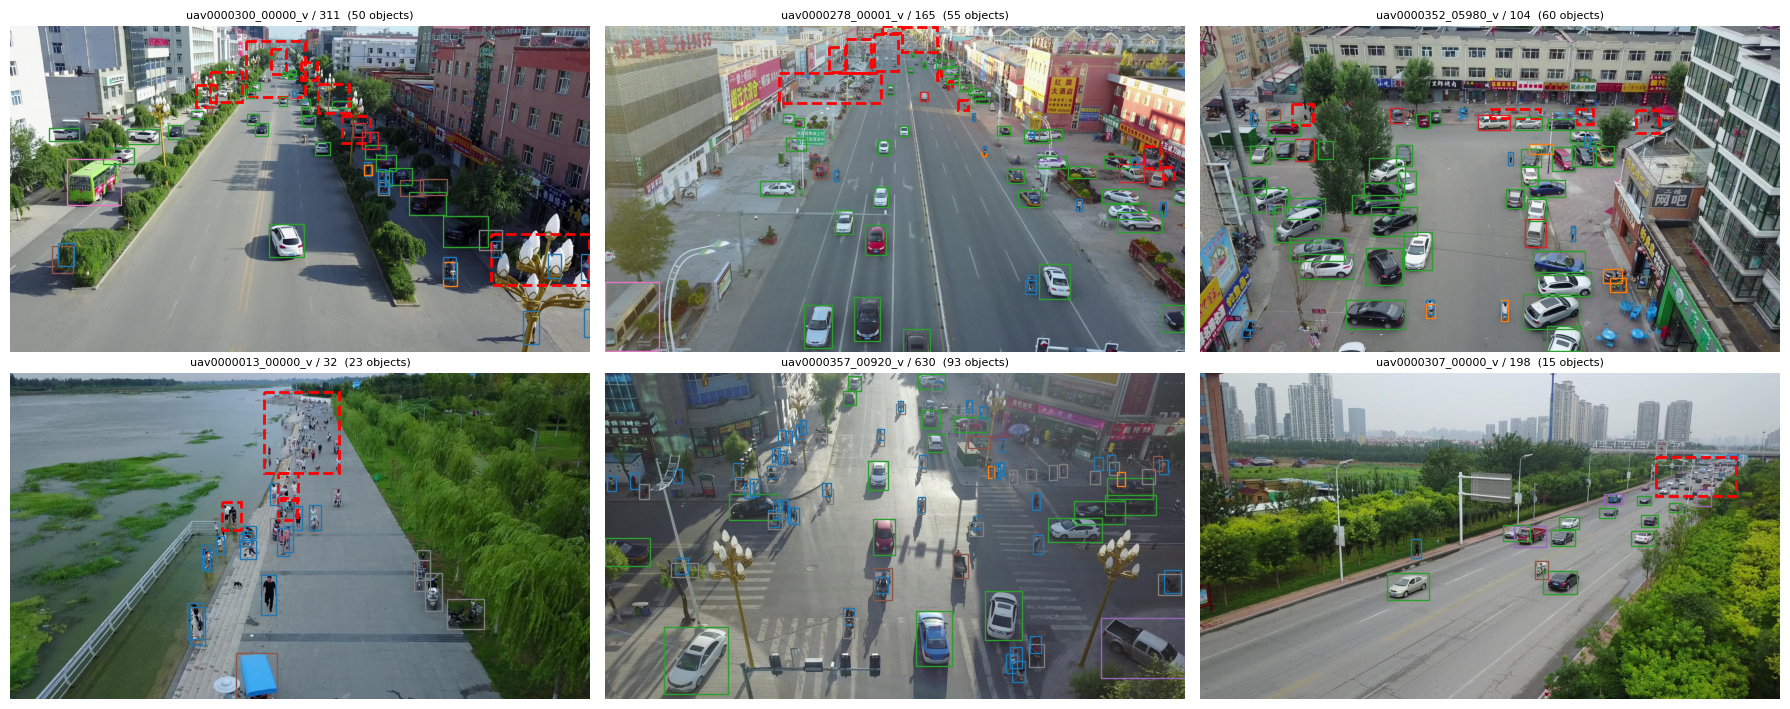

In [13]:
if RUN_EDA:
    cmap = plt.get_cmap("tab10")

    def show_gt(split, n=6, seed=0):
        d = DATA[split]
        sel = d["imgs"].sample(n, random_state=seed)
        a = d["anns"][d["anns"].image_id.isin(sel.id)]
        cols = 3
        fig, axes = plt.subplots((n + cols - 1) // cols, cols, figsize=(6 * cols, 3.6 * ((n + cols - 1) // cols)))
        for ax, r in zip(np.atleast_1d(axes).flatten(), sel.itertuples()):
            ax.imshow(Image.open(ROOT / split / r.file_name))
            g = a[a.image_id == r.id]
            for q in g[g.iscrowd == 1].drop_duplicates(["x", "y", "w", "h"]).itertuples():
                ax.add_patch(patches.Rectangle((q.x, q.y), q.w, q.h, fill=False, ec="red", lw=2, ls="--"))
            for q in g[g.iscrowd == 0].itertuples():
                ax.add_patch(patches.Rectangle((q.x, q.y), q.w, q.h, fill=False, ec=cmap((q.category_id - 1) % 10), lw=1))
            ax.set_title(f"{r.video} / {r.frame_id}  ({(g.iscrowd == 0).sum()} objects)", fontsize=8); ax.axis("off")
        plt.tight_layout(); plt.show()

    show_gt("train")

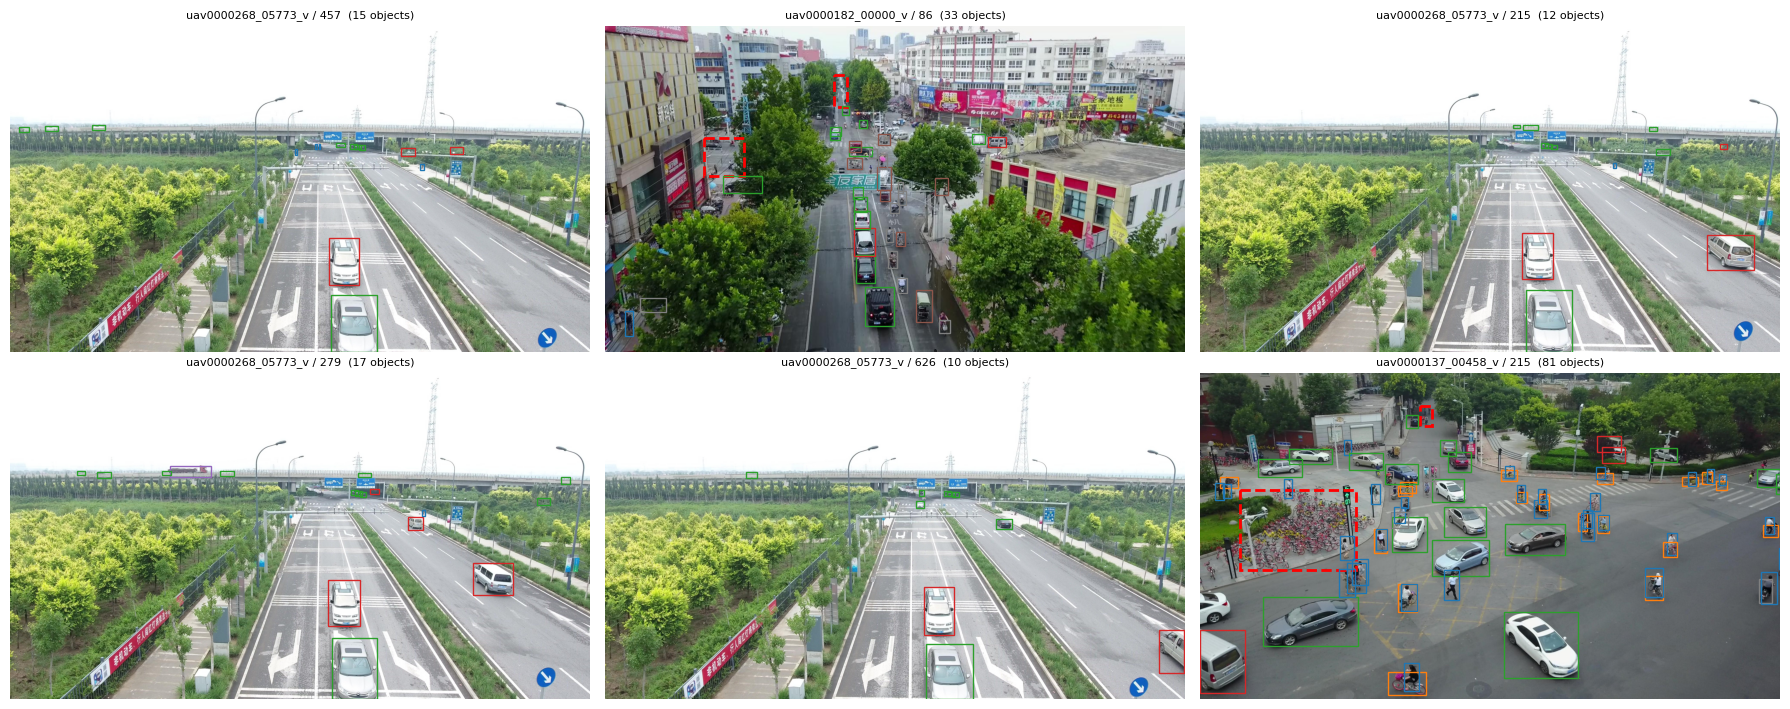

In [14]:
if RUN_EDA:
    show_gt("val", seed=1)

### 3.3 YOLO labels vs COCO annotations

In [15]:
if RUN_EDA:
    def yolo_label_path(split, file_name):
        return ROOT / split / "labels" / Path(file_name).relative_to("images").with_suffix(".txt")

    def check_labels(split, n=200, seed=0):
        d = DATA[split]
        sel = d["imgs"].sample(min(n, len(d["imgs"])), random_state=seed)
        o = objects(split)
        o = o[o.image_id.isin(sel.id)]
        n_coco = o.groupby("image_id").size().reindex(sel.id, fill_value=0).values
        n_yolo, cls_yolo = [], []
        for r in sel.itertuples():
            p = yolo_label_path(split, r.file_name)
            lines = [l.split() for l in p.read_text().splitlines() if l.strip()] if p.exists() else []
            n_yolo.append(len(lines)); cls_yolo += [int(l[0]) for l in lines]
        n_yolo = np.array(n_yolo)
        print(f"{split}: frames with identical object count {(n_coco == n_yolo).mean():.1%} | total COCO {n_coco.sum()} vs YOLO {n_yolo.sum()}")
        h_y = np.bincount(cls_yolo, minlength=len(CATS)) / max(len(cls_yolo), 1)
        h_c = np.bincount(o.category_id.values - 1, minlength=len(CATS)) / max(len(o), 1)
        print("  class shares YOLO:", h_y.round(3).tolist())
        print("  class shares COCO:", h_c.round(3).tolist())

    check_labels("train"); check_labels("val")

train: frames with identical object count 100.0% | total COCO 9187 vs YOLO 9187
  class shares YOLO: [0.313, 0.037, 0.433, 0.04, 0.023, 0.04, 0.009, 0.105]
  class shares COCO: [0.313, 0.037, 0.433, 0.04, 0.023, 0.04, 0.009, 0.105]
val: frames with identical object count 100.0% | total COCO 8174 vs YOLO 8174
  class shares YOLO: [0.448, 0.062, 0.274, 0.054, 0.01, 0.044, 0.003, 0.105]
  class shares COCO: [0.448, 0.062, 0.274, 0.054, 0.01, 0.044, 0.003, 0.105]


## A4. Subsampling and ignored regions
- split: given by organisers, train and val are different videos (checked above), so no leakage between frames of one video
- every 4th frame (justified in 2.5)
- ignored regions (`iscrowd=1`) are painted grey in the training frames and not used as targets. In the val ground truth they stay as `iscrowd=1`, so COCO eval skips detections inside them.
- non-target classes: original ids 0 (ignored region) and 11 (others) are turned into `iscrowd=1` regions by the organisers, each region is repeated once per class (510 744 = 8 x 63 843 unique regions). Other original classes are merged into 8 target classes (table in A1).

In [16]:
if not READY:
    def select_frames(imgs, step):
        """Every step-th frame of every video (sorted by frame number)."""
        imgs = imgs.sort_values(["video_id", "frame_id"]).copy()
        imgs["rank"] = imgs.groupby("video_id").cumcount()
        return imgs[imgs["rank"] % step == 0]

    def build_subset(split, step, mask):
        d = DATA[split]
        sel = select_frames(d["imgs"], step)
        crowd = d["anns"][(d["anns"].iscrowd == 1) & d["anns"].image_id.isin(sel.id)]
        regions = {k: g[["x", "y", "w", "h"]].values
                   for k, g in crowd.drop_duplicates(["image_id", "x", "y", "w", "h"]).groupby("image_id")}
        for r in tqdm(list(sel.itertuples()), desc=split):
            src, dst = ROOT / split / r.file_name, OUT / split / r.file_name
            dst.parent.mkdir(parents=True, exist_ok=True)
            if mask and r.id in regions:
                img = Image.open(src).convert("RGB")
                for x, y, w, h in regions[r.id]:
                    img.paste((114, 114, 114), (int(x), int(y), int(x + w), int(y + h)))
                img.save(dst, quality=95)
            else:
                shutil.copy2(src, dst)
            lab_src = yolo_label_path(split, r.file_name)
            lab_dst = OUT / split / "labels" / Path(r.file_name).relative_to("images").with_suffix(".txt")
            lab_dst.parent.mkdir(parents=True, exist_ok=True)
            if lab_src.exists():
                shutil.copy2(lab_src, lab_dst)
            else:
                lab_dst.write_text("")          # frame without objects
        return sel

    OUT.mkdir(parents=True, exist_ok=True)
    sel_train = build_subset("train", STEP_TRAIN, MASK_IGNORED)
    sel_val = build_subset("val", STEP_VAL, False)
    print(len(sel_train), "train frames,", len(sel_val), "val frames")

train:   0%|          | 0/6072 [00:00<?, ?it/s]

val:   0%|          | 0/714 [00:00<?, ?it/s]

6072 train frames, 714 val frames


In [17]:
if not READY:
    # COCO json of both subsets (ground truth for the evaluation with pycocotools, annotations for torchvision models)
    def subset_coco(split, sel):
        a = DATA[split]["anns"]
        a = a[a.image_id.isin(sel.id)]
        return {
            "info": META["info"],
            "categories": META["categories"],
            "images": [{"id": int(r.id), "file_name": r.file_name, "width": int(r.width), "height": int(r.height),
                        "video_id": int(r.video_id), "video": r.video, "frame_id": int(r.frame_id)} for r in sel.itertuples()],
            "annotations": [{"id": int(r.id), "image_id": int(r.image_id), "category_id": int(r.category_id),
                             "bbox": [r.x, r.y, r.w, r.h],
                             "area": float(r.area) if pd.notna(r.area) else float(r.w * r.h),
                             "iscrowd": int(r.iscrowd),
                             "track_id": int(r.track_id) if pd.notna(r.track_id) else -1} for r in a.itertuples()],
        }

    for split, sel in (("train", sel_train), ("val", sel_val)):
        js = subset_coco(split, sel)
        (OUT / f"{split}_sub.json").write_text(json.dumps(js))
        n_obj = sum(a["iscrowd"] == 0 for a in js["annotations"])
        print(f"{split}_sub.json: {len(js['images'])} frames, {n_obj} objects")
    (OUT / "subset_info.json").write_text(json.dumps({"step_train": STEP_TRAIN, "step_val": STEP_VAL, "mask_ignored": MASK_IGNORED,
                                                      "n_train": len(sel_train), "n_val": len(sel_val), "seed": SEED}))

train_sub.json: 6072 frames, 277673 objects
val_sub.json: 714 frames, 28685 objects


### 4.1 What the model sees
Train frames after resize and masking.

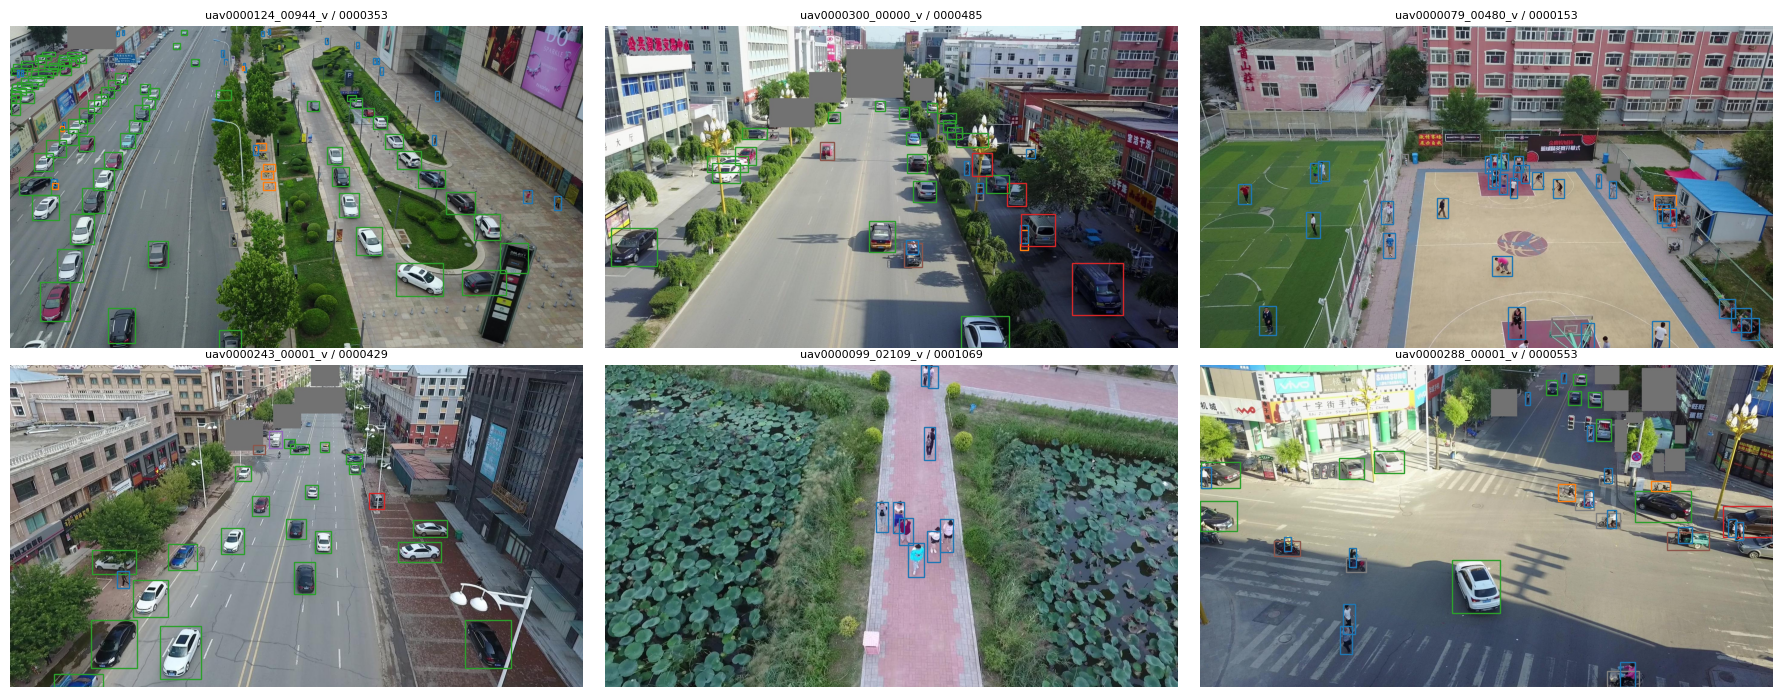

size of OUT: 3.55 GB


In [18]:
if RUN_EDA:
    files = sorted((OUT / "train" / "images").rglob("*.jpg"))
    pick = random.Random(1).sample(files, min(6, len(files)))
    fig, axes = plt.subplots(2, 3, figsize=(18, 7))
    for ax, f in zip(axes.flatten(), pick):
        img = Image.open(f); W, H = img.size
        ax.imshow(img)
        lab = OUT / "train" / "labels" / f.relative_to(OUT / "train" / "images").with_suffix(".txt")
        for l in lab.read_text().splitlines():
            c, cx, cy, w, h = l.split(); c = int(c); cx, cy, w, h = (float(v) for v in (cx, cy, w, h))
            ax.add_patch(patches.Rectangle(((cx - w / 2) * W, (cy - h / 2) * H), w * W, h * H, fill=False, ec=cmap(c % 10), lw=1))
        ax.set_title(f"{f.parent.name} / {f.stem}", fontsize=8); ax.axis("off")
    plt.tight_layout(); plt.show()
    print("size of OUT: %.2f GB" % (sum(p.stat().st_size for p in OUT.rglob("*") if p.is_file()) / 1e9))

In [19]:
# dataset config for Ultralytics, and the val ground truth for the COCO evaluation
VAL_JSON = OUT / "val_sub.json"
names = [c["name"] for c in sorted(json.loads(VAL_JSON.read_text())["categories"], key=lambda c: c["id"])]
yaml_path = WORK / "data.yaml"
yaml_path.write_text(
    f"path: {OUT}\ntrain: train/images\nval: val/images\nnames:\n"
    + "\n".join(f"  {i}: {n}" for i, n in enumerate(names)) + "\n")
print(yaml_path.read_text())
print(json.loads((OUT / "subset_info.json").read_text()))

path: /kaggle/temp/hw2_sub
train: train/images
val: val/images
names:
  0: person
  1: bicycle
  2: car
  3: van
  4: truck
  5: tricycle
  6: bus
  7: motor

{'step_train': 4, 'step_val': 4, 'mask_ignored': True, 'n_train': 6072, 'n_val': 714, 'seed': 42}


## A5. Preprocessing and augmentation
- **Resize**: long side -> `imgsz` (640 for the baselines, 960 in tuned variants), aspect ratio kept. Ultralytics pads (letterbox), torchvision models get the unpadded image.
- **Normalisation**: pixels /255 for YOLO/RT-DETR; torchvision models normalise with ImageNet mean/std inside the model.
- **Augmentation**: Ultralytics defaults (mosaic, scale, HSV, horizontal flip), mosaic off in the last 2 epochs. torchvision: horizontal flip only. This is an unequal setup and I will mention it as a limitation in the report.
- **Seeds**: `SEED = 42` everywhere.

## Observations -> decisions (numbers from the first EDA run, check them against your outputs)
| Observation | Decision |
|---|---|
| mean 46, max 180 objects per frame | `MAX_DET = 300`; RT-DETR has 300 queries, fewer queries are tested in `rtdetr_nq150` |
| median object is 2.4% of frame width = ~15 px at 640; 9.8% of objects < 8 px at 640, 1.7% at 960 | try `imgsz` 960, small anchors, extra P2 head |
| default anchors start at 32 px | data-driven anchors (C2) |
| car 46% and person 30% of train, bus 0.9% | report per-class AP, bus is almost unlearnable |
| val class mix differs from train (person 44% in val) | do not trust one class |
| objects move 0.17 box sizes in 4 frames | step 4 loses little |
| val has 34% frames at 3840 px, test has 680-1920 px and no frames above 1920 | pixel-based AP_small on val is not the same as on test, do not over-tune on val |
| 75% of train frames contain ignored regions (~2.4% area) | mask them |

# Part B. Evaluation protocol (same for every model)
COCO mAP@[.5:.95], AP50, AP75, AP small/medium/large (by pixel area in the original frame) with `pycocotools` on `val_sub.json`.
Ignored regions are `iscrowd=1`, so detections inside them are not counted as false positives.
Speed = milliseconds per image (forward + post-processing, without reading the file), batch size 1 for torchvision, Ultralytics own timing for YOLO/RT-DETR.
Detections are stored per run in `dets_<run>.pkl` for the error analysis.

In [20]:
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

with contextlib.redirect_stdout(io.StringIO()):
    GT = COCO(str(VAL_JSON))
VAL_IDS = sorted(GT.imgs)
if N_VAL_CAP:     # smoke test: evenly spaced frames, so that every val video is represented
    VAL_IDS = [VAL_IDS[i] for i in np.linspace(0, len(VAL_IDS) - 1, min(N_VAL_CAP, len(VAL_IDS))).astype(int)]
VAL_PATHS = [str(OUT / "val" / GT.imgs[i]["file_name"]) for i in VAL_IDS]
CLASS_NAMES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]  # class index 0..7

def run_predict(predict_fn, ids, paths):
    # predict_fn(paths) yields (boxes_xyxy, scores, classes 0..7, (h, w), ms) per image
    dets, ms = [], []
    for iid, (b, s, c, shp, t) in zip(ids, predict_fn(paths)):
        dets.append({"image_id": iid, "boxes": np.asarray(b, dtype=np.float32).reshape(-1, 4),
                     "scores": np.asarray(s, dtype=np.float32), "classes": np.asarray(c, dtype=np.int64)})
        ms.append(t)
    return dets, float(np.mean(ms))

def to_coco_dets(dets):
    out = []
    for d in dets:
        for (x1, y1, x2, y2), s, c in zip(d["boxes"], d["scores"], d["classes"]):
            out.append({"image_id": int(d["image_id"]), "category_id": int(c) + 1,
                        "bbox": [float(x1), float(y1), float(x2 - x1), float(y2 - y1)], "score": float(s)})
    return out

def _ap(E, iou=None, area=0):
    # mean precision from the accumulated COCOeval; area: 0 all, 1 small, 2 medium, 3 large
    # (E.stats cannot be used because maxDets is [1, 10, MAX_DET] instead of 100)
    p = E.eval["precision"]                      # [IoU, recall, class, area, maxDets]
    if iou is not None:
        p = p[np.isclose(E.params.iouThrs, iou)]
    p = p[:, :, :, area, -1]
    p = p[p > -1]
    return float(p.mean()) if p.size else 0.0

def coco_eval_from(dets, ms=None, ids=None, per_class=False):
    ids = list(ids) if ids is not None else VAL_IDS
    keep = set(ids)
    cd = to_coco_dets([d for d in dets if d["image_id"] in keep])
    keys = ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large"]
    if not cd:
        return {k: 0.0 for k in keys}
    with contextlib.redirect_stdout(io.StringIO()):
        E = COCOeval(GT, GT.loadRes(cd), "bbox")
        E.params.imgIds = ids
        E.params.maxDets = [1, 10, MAX_DET]
        E.evaluate(); E.accumulate()
    r = {"mAP": _ap(E), "AP50": _ap(E, 0.5), "AP75": _ap(E, 0.75),
         "AP_small": _ap(E, area=1), "AP_medium": _ap(E, area=2), "AP_large": _ap(E, area=3)}
    if ms is not None:
        r["ms_per_img"] = ms
    if per_class:
        p = E.eval["precision"]  # T, R, K, A, M
        for k, n in enumerate(CLASS_NAMES):
            x = p[:, :, k, 0, -1]
            r["AP_" + n] = float(x[x > -1].mean()) if (x > -1).any() else 0.0
    return r

# Part C. Models
Four families, all start from COCO-pretrained weights and get the same epoch budget:

| family | model | library |
|---|---|---|
| two-stage anchor-based | Faster R-CNN ResNet50-FPN v2 | torchvision |
| one-stage anchor-based | RetinaNet ResNet50-FPN v2 | torchvision |
| one-stage anchor-free | YOLO11s | ultralytics |
| query-based | RT-DETR-L | ultralytics |

Every experiment is a named variant. `RUN` in the config picks which ones to train in this session.

## C1. Variants
Each variant changes one thing (or a clearly named group) relative to its `*_base`.
Minimum for the rubric: base + at least 2 variants per family. `*_tuned` combines changes, edit it after looking at the results.

| family | variant | change |
|---|---|---|
| Faster R-CNN | `frcnn_rpn` | more RPN proposals (train 2000->3000, test 1000->2000) |
| | `frcnn_roi` | RoI positive fraction 0.25 -> 0.5 |
| | `frcnn_loss` | smooth L1 (beta 1/9) -> plain L1 box loss |
| | `frcnn_anch` | RPN anchors from k-means on the data (C2) |
| RetinaNet | `retina_l1` | box loss GIoU (used in `retina_base`) -> L1 |
| | `retina_anch` | anchors from k-means on the data |
| | `retina_focal` | focal loss gamma 2.0 -> 1.0 |
| | `retina_iou` | positive/negative IoU thresholds 0.5/0.4 -> 0.4/0.3 |
| YOLO11 | `yolo_960` | input size 640 -> 960 |
| | `yolo_box` | box loss gain 7.5 -> 12 |
| | `yolo_p2` | extra high-resolution P2 head (stride 4) |
| RT-DETR | `rtdetr_lr` | AdamW lr 0.0001 (the usual DETR value) instead of 0.000833 |
| | `rtdetr_nq150` | 150 queries instead of 300 (train: p99 = 142 objects per frame, max 180; val max 116) |
| | `rtdetr_dn` | denoising queries 100 -> 200 (a dense frame has more than 100 boxes, so only a random subset was denoised) |
| | `rtdetr_match` | matching cost: GIoU weight 2 -> 5, L1 weight 5 -> 2 (L1 on normalised coordinates is dominated by large boxes) |
| | `rtdetr_960` | input size 960 |

The Ultralytics RT-DETR has no separate learning rate for the backbone and the transformer, so this tuning option is not available (mention it in the report).

In [21]:
FR = dict(kind="frcnn", lr=0.01, sched="cos", rpn_pre_train=2000, rpn_post_train=2000, rpn_pre_test=1000,
          rpn_post_test=1000, roi_batch=512, roi_pos=0.25, beta=1 / 9, anchors="default")
RT = dict(kind="retina", lr=0.005, sched="cos", alpha=0.25, gamma=2.0, fg=0.5, bg=0.4, box_loss="giou", anchors="default")
# YOLO11 with an extra P2 (stride 4) detection head. This Ultralytics version has no built-in yolo11-p2.yaml,
# so the config is written here. The 's' in the file name selects the width/depth scale of YOLO11s.
P2_YAML = """\
nc: 80
scales:
  n: [0.50, 0.25, 1024]
  s: [0.50, 0.50, 1024]
  m: [0.50, 1.00, 512]
  l: [1.00, 1.00, 512]
  x: [1.00, 1.50, 512]
backbone:
  - [-1, 1, Conv, [64, 3, 2]]            # 0  P1/2
  - [-1, 1, Conv, [128, 3, 2]]           # 1  P2/4
  - [-1, 2, C3k2, [256, False, 0.25]]    # 2
  - [-1, 1, Conv, [256, 3, 2]]           # 3  P3/8
  - [-1, 2, C3k2, [512, False, 0.25]]    # 4
  - [-1, 1, Conv, [512, 3, 2]]           # 5  P4/16
  - [-1, 2, C3k2, [512, True]]           # 6
  - [-1, 1, Conv, [1024, 3, 2]]          # 7  P5/32
  - [-1, 2, C3k2, [1024, True]]          # 8
  - [-1, 1, SPPF, [1024, 5]]             # 9
  - [-1, 2, C2PSA, [1024]]               # 10
head:
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]   # 11
  - [[-1, 6], 1, Concat, [1]]                    # 12 cat backbone P4
  - [-1, 2, C3k2, [512, False]]                  # 13
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]   # 14
  - [[-1, 4], 1, Concat, [1]]                    # 15 cat backbone P3
  - [-1, 2, C3k2, [256, False]]                  # 16 (P3/8)
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]   # 17
  - [[-1, 2], 1, Concat, [1]]                    # 18 cat backbone P2
  - [-1, 2, C3k2, [128, False]]                  # 19 (P2/4, new small-object head)
  - [-1, 1, Conv, [128, 3, 2]]                   # 20
  - [[-1, 16], 1, Concat, [1]]                   # 21 cat head P3
  - [-1, 2, C3k2, [256, False]]                  # 22 (P3/8)
  - [-1, 1, Conv, [256, 3, 2]]                   # 23
  - [[-1, 13], 1, Concat, [1]]                   # 24 cat head P4
  - [-1, 2, C3k2, [512, False]]                  # 25 (P4/16)
  - [-1, 1, Conv, [512, 3, 2]]                   # 26
  - [[-1, 10], 1, Concat, [1]]                   # 27 cat head P5
  - [-1, 2, C3k2, [1024, True]]                  # 28 (P5/32)
  - [[19, 22, 25, 28], 1, Detect, [nc]]          # Detect(P2, P3, P4, P5)
"""
P2_PATH = WORK / "yolo11s-p2.yaml"
P2_PATH.write_text(P2_YAML)

YO = dict(kind="yolo", model="yolo11s.pt", imgsz=640, batch=16, cache=CACHE, args={})
RD = dict(kind="rtdetr", model="rtdetr-l.pt", imgsz=640, batch=8, cache=CACHE, args={})

VARIANTS = {
    # two-stage
    "frcnn_base": {**FR},
    "frcnn_rpn":  {**FR, "rpn_pre_train": 3000, "rpn_post_train": 3000, "rpn_pre_test": 2000, "rpn_post_test": 2000},
    "frcnn_roi":  {**FR, "roi_pos": 0.5},
    "frcnn_loss": {**FR, "beta": 0.0},
    "frcnn_anch": {**FR, "anchors": "data"},
    "frcnn_tuned": {**FR, "rpn_pre_train": 3000, "rpn_post_train": 3000, "rpn_pre_test": 2000, "rpn_post_test": 2000,
                    "anchors": "data"},          # EDIT after results
    # one-stage anchor-based
    "retina_base":  {**RT},
    "retina_l1":    {**RT, "box_loss": "l1"},
    "retina_anch":  {**RT, "anchors": "data"},
    "retina_anch2": {**RT, "anchors": "half"},     # stride-aware fix of retina_anch
    "retina_focal": {**RT, "gamma": 1.0},
    "retina_iou":   {**RT, "fg": 0.4, "bg": 0.3},
    "retina_tuned": {**RT, "anchors": "half", "fg": 0.4, "bg": 0.3},   # retina_anch2 + lower IoU thresholds (more positives for small boxes)
    # one-stage anchor-free
    "yolo_base": {**YO},
    "yolo_960":  {**YO, "imgsz": 960, "batch": 8, "cache": "disk"},
    "yolo_1280": {**YO, "imgsz": 1280, "batch": 4, "cache": "disk"},     # resolution search: 640 / 960 / 1280
    "yolo_step2":  {**YO},      # data experiment, see DATA_VARIANTS (config cell)
    "yolo_nomask": {**YO},      # data experiment, see DATA_VARIANTS (config cell)
    "yolo_box":  {**YO, "args": {"box": 12.0}},
    "yolo_p2":   {**YO, "model": str(P2_PATH), "pretrained_from": "yolo11s.pt"},
    "yolo_tuned": {**YO, "model": str(P2_PATH), "pretrained_from": "yolo11s.pt", "imgsz": 960, "batch": 8,
                   "cache": "disk"},             # EDIT after results
    # query-based
    "rtdetr_base": {**RD},
    "rtdetr_lr":   {**RD, "args": {"optimizer": "AdamW", "lr0": 0.0001}},
    "rtdetr_nq150": {**RD, "dec": {"num_queries": 150}},
    "rtdetr_dn":    {**RD, "dec": {"num_denoising": 200}},
    "rtdetr_match": {**RD, "cost": {"giou": 5.0, "bbox": 2.0}},
    "rtdetr_960":  {**RD, "imgsz": 960, "batch": 4, "cache": "disk"},
    "rtdetr_tuned": {**RD, "dec": {"num_queries": 150, "num_denoising": 200}, "cost": {"giou": 5.0, "bbox": 2.0}},   # EDIT after results
}
for n in RUN:
    assert n in VARIANTS, f"unknown variant {n}"
print(len(VARIANTS), "variants defined; this session:", RUN)

28 variants defined; this session: []


## C2. Anchors from the data
Object sizes are taken from `train_sub.json` and rescaled to the network input (long side = `IMGSZ_TV`).
Sizes (sqrt of area) are clustered with 1-D k-means in log space: 15 centres for RetinaNet (3 per FPN level), 5 for Faster R-CNN (1 per level).
`coverage` = for each ground-truth box, the best IoU with any anchor *shape* (centres aligned). It is optimistic, but shows if the shapes fit.

In [22]:
from sklearn.cluster import KMeans

_tr = json.loads((OUT / "train_sub.json").read_text())
_long = {i["id"]: max(i["width"], i["height"]) for i in _tr["images"]}
_b = np.array([[_long[a["image_id"]], a["bbox"][2], a["bbox"][3]] for a in _tr["annotations"] if a["iscrowd"] == 0], dtype=float)
del _tr
_k = IMGSZ_TV / _b[:, 0]
BOX_WH = np.stack([_b[:, 1] * _k, _b[:, 2] * _k], 1)          # box width, height at network input scale
SZ_TV = np.sqrt(BOX_WH[:, 0] * BOX_WH[:, 1])

def data_sizes(k):
    km = KMeans(k, n_init=5, random_state=SEED).fit(np.log(SZ_TV.clip(2))[:, None])
    return sorted(int(round(np.exp(c))) for c in km.cluster_centers_[:, 0])

def coverage(levels, strides=None, ratios=(0.5, 1.0, 2.0), n=30000):
    """Share of boxes that no anchor matches with IoU >= 0.5.
    strides=None: box and anchor centres coincide (optimistic).
    strides=[...]: anchors only sit on the feature-map grid, so the box centre is up to stride/2 away from the nearest
    anchor centre; this is what really happens and it hurts when anchors are much smaller than the stride."""
    rng = np.random.default_rng(SEED)
    wh = BOX_WH[rng.choice(len(BOX_WH), min(n, len(BOX_WH)), replace=False)]
    best = np.zeros(len(wh))
    for li, lv in enumerate(levels):
        off = rng.uniform(-0.5, 0.5, wh.shape) * strides[li] if strides is not None else np.zeros_like(wh)
        for s in lv:
            for r in ratios:
                aw, ah = s / np.sqrt(r), s * np.sqrt(r)
                iw = np.clip(np.minimum(off[:, 0] + wh[:, 0] / 2, aw / 2) - np.maximum(off[:, 0] - wh[:, 0] / 2, -aw / 2), 0, None)
                ih = np.clip(np.minimum(off[:, 1] + wh[:, 1] / 2, ah / 2) - np.maximum(off[:, 1] - wh[:, 1] / 2, -ah / 2), 0, None)
                inter = iw * ih
                best = np.maximum(best, inter / (wh[:, 0] * wh[:, 1] + aw * ah - inter))
    return {"mean_best_iou": round(float(best.mean()), 3), "share_below_0.5": round(float((best < 0.5).mean()), 3)}

DEF_RETINA = [(x, int(x * 2 ** (1 / 3)), int(x * 2 ** (2 / 3))) for x in [32, 64, 128, 256, 512]]
DEF_FRCNN = [(32,), (64,), (128,), (256,), (512,)]
_s15, _s5 = data_sizes(15), data_sizes(5)
DATA_RETINA = [tuple(_s15[3 * i:3 * i + 3]) for i in range(5)]
DATA_FRCNN = [(s,) for s in _s5]

HALF_RETINA = [tuple(int(round(v / 2)) for v in lv) for lv in DEF_RETINA]       # default sizes / 2 (about 2x the stride)
RET_STRIDES, FR_STRIDES = [8, 16, 32, 64, 128], [4, 8, 16, 32, 64]

print(f"object sqrt(area) at {IMGSZ_TV}px: p10/p50/p90 =", np.percentile(SZ_TV, [10, 50, 90]).round(1))
for n, lv, st in [("RetinaNet default", DEF_RETINA, RET_STRIDES), ("RetinaNet data", DATA_RETINA, RET_STRIDES),
                  ("RetinaNet default/2", HALF_RETINA, RET_STRIDES),
                  ("Faster R-CNN default", DEF_FRCNN, FR_STRIDES), ("Faster R-CNN data", DATA_FRCNN, FR_STRIDES)]:
    print(f"{n:20s} centred: {coverage(lv)} | on the stride grid: {coverage(lv, st)}")
    print(" " * 20, lv)


object sqrt(area) at 640px: p10/p50/p90 = [ 8.  15.2 33.2]
RetinaNet default    centred: {'mean_best_iou': 0.322, 'share_below_0.5': 0.772} | on the stride grid: {'mean_best_iou': 0.31, 'share_below_0.5': 0.773}
                     [(32, 40, 50), (64, 80, 101), (128, 161, 203), (256, 322, 406), (512, 645, 812)]
RetinaNet data       centred: {'mean_best_iou': 0.834, 'share_below_0.5': 0.002} | on the stride grid: {'mean_best_iou': 0.371, 'share_below_0.5': 0.83}
                     [(4, 6, 7), (9, 10, 12), (14, 17, 20), (23, 27, 33), (41, 52, 78)]
RetinaNet default/2  centred: {'mean_best_iou': 0.647, 'share_below_0.5': 0.283} | on the stride grid: {'mean_best_iou': 0.535, 'share_below_0.5': 0.365}
                     [(16, 20, 25), (32, 40, 50), (64, 80, 102), (128, 161, 203), (256, 322, 406)]
Faster R-CNN default centred: {'mean_best_iou': 0.308, 'share_below_0.5': 0.772} | on the stride grid: {'mean_best_iou': 0.305, 'share_below_0.5': 0.772}
                     [(32,), (64,), (1

## C3. torchvision: data, training loop, prediction
Frames are read from the resized subset, shrunk so the long side is `IMGSZ_TV`, boxes scaled the same way.
Training: SGD momentum 0.9, wd 1e-4, linear warm-up then cosine (or step) schedule, mixed precision, gradient clipping 10, horizontal flip.
Predictions are scaled back to the original frame size, so every model is evaluated in the same coordinates.

In [23]:
import torch.nn as nn, torch.nn.functional as F, torchvision
from torch.utils.data import Dataset, DataLoader
from functools import partial

def free_gpu():
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()

def load_img(path, imgsz):
    im = Image.open(path)
    W, H = im.size
    s = imgsz / max(W, H)
    nw, nh = max(1, round(W * s)), max(1, round(H * s))
    im.draft("RGB", (nw, nh))                       # fast JPEG downscale
    im = im.convert("RGB").resize((nw, nh), Image.BILINEAR)
    x = torch.from_numpy(np.asarray(im).copy()).permute(2, 0, 1).float() / 255
    return x, s, (H, W)

class DetData(Dataset):
    # labels are COCO category ids 1..8, 0 = background (torchvision convention)
    def __init__(self, split, imgsz, train, cap=None):
        js = json.loads((OUT / f"{split}_sub.json").read_text())
        self.split, self.imgsz, self.train = split, imgsz, train
        self.imgs = sorted(js["images"], key=lambda r: r["id"])
        if cap:
            self.imgs = random.Random(SEED).sample(self.imgs, min(cap, len(self.imgs)))
        self.anns = defaultdict(list)
        for a in js["annotations"]:
            if a["iscrowd"] == 0:
                self.anns[a["image_id"]].append(a)
    def __len__(self):
        return len(self.imgs)
    def __getitem__(self, i):
        r = self.imgs[i]
        x, s, _ = load_img(OUT / self.split / r["file_name"], self.imgsz)
        an = self.anns[r["id"]]
        b = np.array([a["bbox"] for a in an], dtype=np.float32).reshape(-1, 4) * s
        b[:, 2:] += b[:, :2]
        b[:, 2] = np.maximum(b[:, 2], b[:, 0] + 1); b[:, 3] = np.maximum(b[:, 3], b[:, 1] + 1)
        lab = np.array([a["category_id"] for a in an], dtype=np.int64)
        if self.train and random.random() < 0.5:    # horizontal flip
            x = x.flip(-1); w = x.shape[-1]
            b[:, [0, 2]] = w - b[:, [2, 0]]
        return x, {"boxes": torch.from_numpy(b), "labels": torch.from_numpy(lab)}

def collate(b):
    return tuple(zip(*b))

def train_tv(model, hp, epochs):
    ds = DetData("train", IMGSZ_TV, True, N_TRAIN_CAP)
    dl = DataLoader(ds, batch_size=TV_BATCH, shuffle=True, num_workers=WORKERS, collate_fn=collate,
                    drop_last=True, generator=torch.Generator().manual_seed(SEED))
    model.cuda().train()
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.SGD(params, lr=hp["lr"], momentum=0.9, weight_decay=1e-4)
    total, warm = epochs * len(dl), min(300, len(dl))
    def factor(it):
        if it < warm:
            return 0.001 + 0.999 * it / warm
        p = (it - warm) / max(1, total - warm)
        if hp["sched"] == "cos":
            return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * p))
        return 1.0 if p < 0.7 else (0.1 if p < 0.9 else 0.01)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, factor)
    scaler = torch.amp.GradScaler("cuda")
    hist, it, skipped = [], 0, 0
    for ep in range(epochs):
        t0, tot, n = time.time(), 0.0, 0
        for imgs, tg in tqdm(dl, desc=f"epoch {ep + 1}/{epochs}", leave=False):
            imgs = [i.cuda(non_blocking=True) for i in imgs]
            tg = [{k: v.cuda() for k, v in t.items()} for t in tg]
            with torch.autocast("cuda", dtype=torch.float16):
                loss = sum(model(imgs, tg).values())
            if not torch.isfinite(loss):
                opt.zero_grad(set_to_none=True); sched.step(); skipped += 1; continue
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, 10.0)
            scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item(); n += 1
        hist.append(round(tot / max(1, n), 4))
        print(f"epoch {ep + 1}/{epochs} | loss {hist[-1]} | skipped (non-finite) steps {skipped} | {(time.time() - t0) / 60:.1f} min")
    return hist

def tv_predict_fn(model, imgsz):
    def fn(paths):
        model.eval()
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):     # warm-up, not timed
            model([torch.zeros(3, imgsz * 9 // 16, imgsz, device="cuda")])
        for p in paths:
            x, s, (h, w) = load_img(p, imgsz)
            x = x.cuda(non_blocking=True)
            torch.cuda.synchronize(); t = time.time()
            with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
                o = model([x])[0]
            torch.cuda.synchronize(); ms = (time.time() - t) * 1000
            keep = (o["labels"] > 0).cpu().numpy()          # RetinaNet head has an unused class-0 slot, never output it
            b = o["boxes"].float().cpu().numpy()[keep] / s
            b[:, [0, 2]] = b[:, [0, 2]].clip(0, w); b[:, [1, 3]] = b[:, [1, 3]].clip(0, h)
            yield b, o["scores"].float().cpu().numpy()[keep], o["labels"].cpu().numpy()[keep] - 1, (h, w), ms
    return fn

## C4. torchvision model builders
**Faster R-CNN**: COCO weights, new 9-way box predictor (8 classes + background). RPN proposal counts, RoI sampling, box loss beta and RPN anchors come from the variant. The box loss is replaced by a copy of torchvision's `fastrcnn_loss` with a configurable `beta` (beta=0 is L1).

**RetinaNet**: COCO weights, the head is rebuilt for 8 classes (towers keep their weights when shapes match). Focal loss alpha/gamma and the IoU thresholds for positives/negatives are configurable, the box loss is GIoU as in torchvision's v2 recipe.

In [24]:
import torchvision.models.detection.roi_heads as RH
import torchvision.models.detection.retinanet as RN
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, retinanet_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.models.detection.retinanet import RetinaNetHead

def make_fastrcnn_loss(beta):
    # same as torchvision's fastrcnn_loss, only beta of the smooth L1 is a parameter
    def fastrcnn_loss(class_logits, box_regression, labels, regression_targets):
        labels = torch.cat(labels, 0); regression_targets = torch.cat(regression_targets, 0)
        cls_loss = F.cross_entropy(class_logits, labels)
        pos = torch.where(labels > 0)[0]
        N = class_logits.shape[0]
        box_regression = box_regression.reshape(N, box_regression.size(-1) // 4, 4)
        box_loss = F.smooth_l1_loss(box_regression[pos, labels[pos]], regression_targets[pos],
                                    beta=beta, reduction="sum") / labels.numel()
        return cls_loss, box_loss
    return fastrcnn_loss

def build_frcnn(hp):
    RH.fastrcnn_loss = make_fastrcnn_loss(hp["beta"])
    m = fasterrcnn_resnet50_fpn_v2(
        weights="COCO_V1", min_size=IMGSZ_TV, max_size=IMGSZ_TV,
        rpn_pre_nms_top_n_train=hp["rpn_pre_train"], rpn_post_nms_top_n_train=hp["rpn_post_train"],
        rpn_pre_nms_top_n_test=hp["rpn_pre_test"], rpn_post_nms_top_n_test=hp["rpn_post_test"],
        box_batch_size_per_image=hp["roi_batch"], box_positive_fraction=hp["roi_pos"],
        box_score_thresh=0.001, box_detections_per_img=MAX_DET)
    m.roi_heads.box_predictor = FastRCNNPredictor(1024, 9)
    if hp["anchors"] == "data":
        m.rpn.anchor_generator = AnchorGenerator(tuple(DATA_FRCNN), ((0.5, 1.0, 2.0),) * 5)
    return m

def build_retina(hp):
    assert hasattr(RN, "sigmoid_focal_loss")
    RN.sigmoid_focal_loss = partial(torchvision.ops.sigmoid_focal_loss, alpha=hp["alpha"], gamma=hp["gamma"])
    m = retinanet_resnet50_fpn_v2(weights="COCO_V1", min_size=IMGSZ_TV, max_size=IMGSZ_TV,
                                  score_thresh=0.001, detections_per_img=MAX_DET,
                                  fg_iou_thresh=hp["fg"], bg_iou_thresh=hp["bg"])
    if hp["anchors"] == "data":
        m.anchor_generator = AnchorGenerator(tuple(DATA_RETINA), ((0.5, 1.0, 2.0),) * 5)
    elif hp["anchors"] == "half":                  # default sizes / 2: small enough for the objects, still ~2x the stride
        m.anchor_generator = AnchorGenerator(tuple(HALF_RETINA), ((0.5, 1.0, 2.0),) * 5)
    na = m.anchor_generator.num_anchors_per_location()[0]
    new = RetinaNetHead(256, na, 9, norm_layer=partial(nn.GroupNorm, 32))
    nsd = new.state_dict()
    new.load_state_dict({k: v for k, v in m.head.state_dict().items() if k in nsd and v.shape == nsd[k].shape}, strict=False)
    new.regression_head._loss_type = hp["box_loss"]
    m.head = new
    return m

@torch.no_grad()
def rpn_recall(model, n_img=150, tops=(100, 300, 1000), thr=0.5):
    # share of GT boxes covered (IoU >= thr) by the top-N RPN proposals = what the first stage delivers
    ds = DetData("val", IMGSZ_TV, False)
    idx = np.linspace(0, len(ds) - 1, min(n_img, len(ds))).astype(int)
    model.eval(); hit, tot = Counter(), 0
    for i in idx:
        x, t = ds[i]
        if len(t["boxes"]) == 0:
            continue
        with torch.autocast("cuda", dtype=torch.float16):
            images, _ = model.transform([x.cuda()])
            props, _ = model.rpn(images, model.backbone(images.tensors))
        iou = torchvision.ops.box_iou(t["boxes"].cuda(), props[0].float())
        for n in tops:
            hit[n] += int((iou[:, :n].max(1).values >= thr).sum()) if iou.shape[1] else 0
        tot += len(t["boxes"])
    return {f"rpn_recall@{n}": round(hit[n] / max(1, tot), 4) for n in tops}

## C5. Ultralytics models (YOLO11, RT-DETR)
Same data yaml for both. Notes:
- GPU memory of the trainer is freed before validation (the first baseline run crashed with out-of-memory otherwise) and prediction uses batch 4.
- `best.pt` is chosen by Ultralytics' own validation (it also counts detections inside ignored regions). The final numbers always come from my COCO evaluation in Part B.
- `results.csv` of each run gives validation mAP per epoch, used for the learning curves in F2.
- RT-DETR variants can set decoder attributes (`dec`: queries, denoising) and matching cost gains (`cost`) through a trainer callback, because the trainer builds its own model.
- The optimizer is fixed to AdamW, lr0 = 0.000833 for all Ultralytics runs (the value `optimizer=auto` chose in the first run), so that variants differ only in what they change.

In [25]:
def ultralytics_predict_fn(model, imgsz, conf=0.001):
    """One frame per call. The frame is shrunk by us to imgsz on the long side (INTER_AREA, as in Ultralytics validation),
    so the network never gets a 3840x2160 tensor (the first version ran out of GPU memory on such val frames).
    Boxes are scaled back to the original frame. Batch 1 also makes speed comparable with the torchvision models."""
    import cv2
    def predict_fn(paths):
        paths = list(paths)
        shapes = []
        try:      # diagnostic: real size of the network input
            hook = model.model.model[0].register_forward_pre_hook(lambda m, a: shapes.append(tuple(a[0].shape)))
        except Exception:
            hook = None

        def one(p):
            img = cv2.imread(p)                                  # BGR, like Ultralytics reads it
            h0, w0 = img.shape[:2]
            r = min(1.0, imgsz / max(h0, w0))                    # only shrink, never enlarge
            if r < 1.0:
                img = cv2.resize(img, (round(w0 * r), round(h0 * r)), interpolation=cv2.INTER_AREA)
            for attempt in (0, 1):
                try:
                    res = model.predict(img, imgsz=imgsz, conf=conf, max_det=MAX_DET, device=DEVICE, verbose=False)[0]
                    return res, r, (h0, w0)
                except torch.cuda.OutOfMemoryError:
                    if attempt:
                        raise
                    free_gpu()                                   # free cached memory and try once more

        if paths:
            one(paths[0])                                        # warm-up, not timed
            print("network input shape (first frame):", shapes[:1] or "not captured", "| imgsz:", imgsz)
        for p in paths:
            res, r, shp = one(p)
            b = res.boxes
            yield (b.xyxy.cpu().numpy() / r, b.conf.cpu().numpy(), b.cls.cpu().numpy().astype(int),
                   shp, sum(res.speed.values()))
        if hook is not None:
            hook.remove()
    return predict_fn

def apply_dec(module, dec):
    # RT-DETR decoder settings: num_queries, num_denoising, label_noise_ratio, box_noise_scale
    head = module.model[-1]
    for k, x in dec.items():
        assert hasattr(head, k), f"RT-DETR decoder has no attribute {k}"
        setattr(head, k, x)

def run_ultra(name, v):
    from ultralytics import YOLO, RTDETR, settings
    try:
        settings.update({"wandb": False, "clearml": False, "comet": False, "raytune": False})
    except Exception:
        pass
    Net = YOLO if v["kind"] == "yolo" else RTDETR
    best = WORK / "runs" / name / "weights" / "best.pt"
    if REUSE_TRAINED and best.exists():
        print(f"reusing trained weights {best} (REUSE_TRAINED = False to retrain)")
    else:
        args = dict(data=str(yaml_path), epochs=EPOCHS, imgsz=v["imgsz"], batch=v["batch"], seed=SEED, deterministic=True,
                    device=DEVICE, workers=WORKERS, cache=v["cache"], project=str(WORK / "runs"), name=name,
                    exist_ok=True, plots=True, close_mosaic=min(CLOSE_MOSAIC, EPOCHS), max_det=MAX_DET, fraction=FRACTION)
        args.setdefault("optimizer", "AdamW")     # fixed on purpose: 'auto' picks AdamW, lr0 0.000833 for nc=8 and ignores lr0
        args.setdefault("lr0", 0.000833)
        args.update(v["args"])
        net = Net(v["model"])
        if v.get("pretrained_from"):
            net.load(v["pretrained_from"])          # copy matching COCO weights into the modified architecture
        if v.get("dec") or v.get("cost"):
            def rtdetr_patch(trainer):
                # the trainer builds its own model, so the settings are applied here (model and EMA copy)
                for mod in (trainer.model, getattr(getattr(trainer, "ema", None), "ema", None)):
                    if mod is not None:
                        apply_dec(mod, v.get("dec", {}))
                if v.get("cost"):                      # Hungarian matching cost gains (class / bbox / giou)
                    m = trainer.model
                    m.criterion = m.init_criterion()
                    m.criterion.matcher.cost_gain.update(v["cost"])
                h = trainer.model.model[-1]
                crit = getattr(trainer.model, "criterion", None)
                print("RT-DETR:", {"queries": h.num_queries, "denoising": h.num_denoising,
                                   "cost_gain": crit.matcher.cost_gain if crit is not None else "default"})
            net.add_callback("on_pretrain_routine_end", rtdetr_patch)
        net.train(**args)
        net.trainer = None                          # drop references to the trainer so that its GPU memory can be freed
        del net; free_gpu()
    if HAS_GPU:
        print("GPU memory allocated before prediction: %.2f GB" % (torch.cuda.memory_allocated() / 1e9))
    model = Net(str(best))
    if v.get("dec"):
        apply_dec(model.model, v["dec"])          # keep the settings for prediction
    return ultralytics_predict_fn(model, v["imgsz"]), model


# Part D. Submission
Format from the competition page (Data tab): **one row per test frame**, columns `image_id, PredictionString`.
`PredictionString` is a space-separated list of groups `class score x y width height`:
- `class` is **0..7** (as the models output it, no +1 shift), see the class table in `CLASS_NAMES`;
- `(x, y)` is the **top-left corner in pixels** of the original frame, not normalised;
- an empty string for a frame without detections (the frame still has a row);
- at most 500 detections per frame are scored (`MAX_DET = 300` here, so the limit is never reached).

`check_submission` is called automatically after every submission file is written.


In [26]:
HEADER = ["image_id", "PredictionString"]
MAX_PER_IMAGE = 500

def make_pred_string(xyxy, scores, classes, W, H):
    """One frame -> 'class score x y w h class score x y w h ...' (class 0..7, x/y top-left, pixels)."""
    xyxy, scores, classes = np.asarray(xyxy, float).reshape(-1, 4), np.asarray(scores, float), np.asarray(classes)
    parts = []
    for i in np.argsort(-scores)[:MAX_PER_IMAGE]:                  # best scores first, at most 500
        x1, y1 = max(0.0, xyxy[i, 0]), max(0.0, xyxy[i, 1])        # clip the box to the frame
        x2, y2 = min(float(W), xyxy[i, 2]), min(float(H), xyxy[i, 3])
        w, h = x2 - x1, y2 - y1
        if round(w, 1) <= 0 or round(h, 1) <= 0:      # would be written as 0.0
            continue
        parts.append(f"{int(classes[i])} {scores[i]:.5f} {x1:.1f} {y1:.1f} {w:.1f} {h:.1f}")
    return " ".join(parts)

def write_submission(predict_fn, path, limit=None):
    test_df = pd.read_csv(ROOT / "test_images.csv")
    if limit:
        test_df = test_df.head(limit)
    paths = [str(ROOT / f) for f in test_df.file_name]
    print(len(paths), "test frames | first:", paths[0])
    rows, size_mismatch, t0 = [], 0, time.time()
    for r, (xyxy, sc, cl, (h, w), ms) in zip(test_df.itertuples(), predict_fn(paths)):
        size_mismatch += (w, h) != (r.width, r.height)
        rows.append((r.image_id, make_pred_string(xyxy, sc, cl, r.width, r.height)))
    pd.DataFrame(rows, columns=HEADER).to_csv(path, index=False)
    print(f"{len(rows)} rows in {time.time() - t0:.0f}s | frames whose real size differs from the CSV: {size_mismatch}")
    return size_mismatch


In [27]:
def check_submission(path, limit=None):
    """Fail loudly if the file does not match the competition format."""
    sub = pd.read_csv(path, keep_default_na=False, dtype=str)       # empty PredictionString must stay ''
    test_df = pd.read_csv(ROOT / "test_images.csv")
    if limit:
        test_df = test_df.head(limit)
    assert list(sub.columns) == HEADER, sub.columns.tolist()
    assert len(sub) == len(test_df), (len(sub), len(test_df))
    assert sub.image_id.is_unique and set(sub.image_id) == set(test_df.image_id), "image_id do not match test_images.csv"
    toks = sub.PredictionString.str.split()
    n_tok = toks.map(len)
    assert (n_tok % 6 == 0).all(), "a PredictionString has a broken group (not 6 numbers per detection)"
    n_det = n_tok // 6
    assert n_det.max() <= MAX_PER_IMAGE, "more than 500 detections in a frame"
    if n_det.sum():
        a = np.array([x for t in toks for x in t], dtype=float).reshape(-1, 6)
        assert set(a[:, 0].astype(int)) <= set(range(8)), "class ids must be 0..7"
        assert (a[:, 1] >= 0).all() and (a[:, 1] <= 1).all(), "score outside [0, 1]"
        assert (a[:, 4:] > 0).all(), "width/height must be positive"
        print("classes in file:", np.bincount(a[:, 0].astype(int), minlength=8).tolist(),
              "| score range: %.4f-%.4f" % (a[:, 1].min(), a[:, 1].max()))
    print(f"submission OK: {len(sub)} rows | frames without detections: {int((n_det == 0).sum())} "
          f"| detections per frame: mean {n_det.mean():.0f}, max {n_det.max()}")
    return sub


# Part E. Train, evaluate, save
For each name in `RUN`: train -> predict on val -> COCO metrics -> save `metrics_<run>.json` and `dets_<run>.pkl` -> (optional) submission.
Look at the printed JSON line, that is what I need to see.
Files written to `/kaggle/working`: `metrics_<run>.json`, `dets_<run>.pkl`, `submission_<run>.csv` (and `submission.csv` = the last run in `SUBMIT_FOR`), `weights_<run>.pt` for torchvision models, `runs/<run>/weights/best.pt` for Ultralytics models.


In [28]:
FAILED = []
for name in RUN:
    try:
        v = VARIANTS[name]
        print("=" * 30, name, "\n", {k: x for k, x in v.items() if k != "args"}, v.get("args", ""))
        t0, extra, model = time.time(), {}, None
        if v["kind"] in ("yolo", "rtdetr"):
            predict_fn, model = run_ultra(name, v)
            imgsz = v["imgsz"]
        else:
            torch.manual_seed(SEED)
            model = build_frcnn(v) if v["kind"] == "frcnn" else build_retina(v)
            extra["loss_per_epoch"] = train_tv(model, v, EPOCHS)
            torch.save(model.state_dict(), WORK / f"{TAG}weights_{name}.pt")   # needed later for ensembles / final inference
            predict_fn, imgsz = tv_predict_fn(model, IMGSZ_TV), IMGSZ_TV
        train_min = (time.time() - t0) / 60

        dets, ms = run_predict(predict_fn, VAL_IDS, VAL_PATHS)
        res = coco_eval_from(dets, ms, per_class=True)
        if v["kind"] == "frcnn":
            extra.update(rpn_recall(model))
        res = {"run": name, "family": v["kind"], "epochs": EPOCHS, "imgsz": imgsz, "train_min": round(train_min, 1),
               **{k: round(x, 4) for k, x in res.items()}, **extra, "smoke": SMOKE,
               "params": json.dumps({k: x for k, x in v.items() if k not in ("kind", "model", "cache", "pretrained_from")}, sort_keys=True)}
        (WORK / f"{TAG}metrics_{name}.json").write_text(json.dumps(res))
        pickle.dump(dets, open(WORK / f"{TAG}dets_{name}.pkl", "wb"))
        print("RESULT", json.dumps({k: x for k, x in res.items() if k not in ("loss_per_epoch", "params")}))

        if name in SUBMIT_FOR:
            sp = WORK / f"submission_{name}.csv"
            write_submission(predict_fn, sp, SUB_LIMIT)
            shutil.copy2(sp, WORK / f"{TAG}submission.csv")   # the last model in SUBMIT_FOR is the one named submission.csv
            check_submission(sp, SUB_LIMIT)
        del model, predict_fn; free_gpu()
    except Exception:
        import traceback; traceback.print_exc()
        FAILED.append(name); print("FAILED:", name, "-> going on with the next run")
        model = predict_fn = None; free_gpu()
print("failed runs:", FAILED or "none")


failed runs: none


In [29]:
# Pack the small result files of this session into ONE zip, so that a single download is enough
import zipfile
PACK_WEIGHTS = False     # True: also put best.pt / weights_*.pt into the zip (can be 100+ MB)

def pack_results():
    out = WORK / ("results_" + "+".join(RUN) + ".zip")
    files = []
    for pat in ["*metrics_*.json", "*dets_*.pkl", "*submission*.csv"]:
        files += WORK.glob(pat)
    runs = WORK / "runs"
    if runs.exists():
        for pat in ["*/results.csv", "*/args.yaml", "*/*.png", "*/*.jpg"]:
            files += runs.glob(pat)
        if PACK_WEIGHTS:
            files += list(runs.glob("*/weights/best.pt")) + list(WORK.glob("*weights_*.pt"))
    files = sorted(set(f for f in files if f != out))
    with zipfile.ZipFile(out, "w", zipfile.ZIP_DEFLATED) as z:
        for f in files:
            z.write(f, f.relative_to(WORK))
    print(f"{out.name}: {len(files)} files, {out.stat().st_size / 1e6:.1f} MB")

pack_results()


results_.zip: 0 files, 0.0 MB


# Part F. Analysis
They read `metrics_*.json`, `dets_*.pkl` and `runs/*/results.csv` from `/kaggle/working`. Results of earlier sessions are copied there first (set `PRIOR_OUTPUTS` in the config).

In [30]:
# copy results of earlier sessions (notebook outputs added as input) into /kaggle/working, existing files are kept
for d in map(Path, PRIOR_OUTPUTS):
    n = 0
    for f in list(d.glob("*metrics_*.json")) + list(d.glob("*dets_*.pkl")) + list(d.glob("runs/*/results.csv")):
        t = WORK / f.relative_to(d)
        if not t.exists():
            t.parent.mkdir(parents=True, exist_ok=True); shutil.copy2(f, t); n += 1
    print(d, "->", n, "files copied")
print(len(list(WORK.glob(f"{TAG}metrics_*.json"))), "metrics files available")


/kaggle/input/datasets/bohdanazubrytska/results-hw2 -> 34 files copied
15 metrics files available


## F1. All models in one table
Same data, same metric, same epoch budget. AP by object size is the breakdown asked for the anchor-free vs anchor-based comparison. `ms_per_img` is measured on the val frames after a warm-up; Ultralytics predicts with batch 4, the torchvision models with batch 1 (not exactly comparable, say so in the report).

In [31]:
rows = [json.loads(p.read_text()) for p in sorted(WORK.glob(f"{TAG}metrics_*.json"))]
cols = ["run", "epochs", "imgsz", "mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "ms_per_img", "train_min"]
if rows:
    df = pd.DataFrame(rows)
    extra_cols = [c for c in df.columns if c.startswith("rpn_recall")]
    show = df[cols + extra_cols].sort_values("run")
    print(show.round(4).to_string(index=False))
    show.to_csv(WORK / f"{TAG}results_summary.csv", index=False)
    print("\nper class AP:")
    print(df[["run"] + [c for c in df.columns if c.startswith("AP_") and c.split("_")[1] in CLASS_NAMES]].round(3).to_string(index=False))
    if "params" in df:
        print("\nvariant settings (what differs from the defaults in C1):")
        print(df[["run", "params"]].to_string(index=False))

         run  epochs  imgsz    mAP   AP50   AP75  AP_small  AP_medium  AP_large  ms_per_img  train_min  rpn_recall@100  rpn_recall@300  rpn_recall@1000
  frcnn_anch      10    640 0.1353 0.2900 0.1113    0.0429     0.1358    0.2665     36.1290       77.9          0.5160          0.6785           0.7937
  frcnn_base      10    640 0.1281 0.2657 0.1077    0.0350     0.1277    0.2693     35.4102       82.7          0.5326          0.6251           0.6286
  frcnn_loss      10    640 0.1291 0.2707 0.1051    0.0387     0.1289    0.2708     36.1069       79.7          0.5313          0.6270           0.6319
 retina_anch      10    640 0.0200 0.0771 0.0040    0.0195     0.0207    0.0257     30.3628       42.4             NaN             NaN              NaN
retina_anch2      10    640 0.1011 0.2279 0.0782    0.0347     0.0889    0.2292     27.7247       40.7             NaN             NaN              NaN
 retina_base      10    640 0.0896 0.1828 0.0781    0.0307     0.0741    0.1945     26.3

## F1b. Val results by frame width
Test frames are 680-1920 px wide, val has 34% frames of 3840 px (almost no pixel-small objects there). `test-like` = val frames up to 1920 px, `high-res` = wider. `small_share` = share of GT with area < 32² px. Look at the `test-like` rows first when choosing the final model.

In [32]:
W_OF = {i: GT.imgs[i]["width"] for i in VAL_IDS}
GROUPS = {f"w={w}": [i for i in VAL_IDS if W_OF[i] == w] for w in sorted(set(W_OF.values()))}
GROUPS["test-like (<=1920)"] = [i for i in VAL_IDS if W_OF[i] <= 1920]
GROUPS["high-res (>1920)"] = [i for i in VAL_IDS if W_OF[i] > 1920]

def by_width(names):
    rows = []
    for n in names:
        f = WORK / f"{TAG}dets_{n}.pkl"
        if not f.exists():
            continue
        dets = pickle.load(open(f, "rb"))
        for g, ids in GROUPS.items():
            if not ids:
                continue
            r = coco_eval_from(dets, ids=ids)
            gt = [a for i in ids for a in GT.imgToAnns[i] if not a["iscrowd"]]
            rows.append({"run": n, "group": g, "frames": len(ids),
                         "small_share": round(float(np.mean([a["area"] < 32 ** 2 for a in gt])), 3) if gt else 0.0,
                         "mAP": round(r["mAP"], 4), "AP50": round(r["AP50"], 4), "AP_small": round(r["AP_small"], 4)})
    if rows:
        print(pd.DataFrame(rows).to_string(index=False))

by_width([p.stem[len(f"{TAG}metrics_"):] for p in sorted(WORK.glob(f"{TAG}metrics_*.json"))])


         run              group  frames  small_share    mAP   AP50  AP_small
  frcnn_anch             w=1344     207        0.374 0.1400 0.3423    0.0597
  frcnn_anch             w=1904     115        0.179 0.2037 0.3472    0.0562
  frcnn_anch             w=2688      59        0.006 0.2221 0.4750    0.0343
  frcnn_anch             w=2720      88        0.078 0.1204 0.2956    0.0089
  frcnn_anch             w=3840     245        0.139 0.0796 0.1134    0.0000
  frcnn_anch test-like (<=1920)     322        0.314 0.1680 0.3409    0.0482
  frcnn_anch   high-res (>1920)     392        0.061 0.1325 0.2956    0.0059
  frcnn_base             w=1344     207        0.374 0.1490 0.3440    0.0464
  frcnn_base             w=1904     115        0.179 0.1851 0.3195    0.0598
  frcnn_base             w=2688      59        0.006 0.2029 0.4142    0.0000
  frcnn_base             w=2720      88        0.078 0.1234 0.2814    0.0027
  frcnn_base             w=3840     245        0.139 0.0853 0.1237    0.0001

## F2. Validation mAP over training: query-based vs CNN-based
From the Ultralytics `results.csv` (mAP50-95 after every epoch, same epoch budget, same data). It is Ultralytics' own validation (it counts detections inside ignored regions), so only the shape of the curves is compared, the final numbers are in F1. The right plot has wall-clock time on the x axis, because "same budget" can also mean the same GPU time.

Technical notes for the query-based section (reference only, write the report text in your own words):
- **Bipartite matching.** Every ground-truth box is matched to exactly one query by the Hungarian algorithm (cost = 2 * class + 5 * L1 + 2 * GIoU in Ultralytics). Matched queries get the box and class as targets, all other queries get "no object". A second query on the same object is therefore always punished, so the model learns to output one box per object and there are no duplicates to remove: the predictions are only sorted by score (top-k), no NMS. A CNN detector gives many positives to one object (several anchors or grid cells), so its raw output has overlapping boxes and needs NMS.
- **Training dynamics.** The assignment depends on the current predictions and changes during training, so early training is unstable and slow. Denoising queries (noised copies of the GT with a fixed assignment) stabilise it (`rtdetr_dn`); the cost weights decide what counts as a good match (`rtdetr_match`).
- **Queries and density.** Each query can explain one object, so `num_queries` must exceed the number of objects in the densest frame (train max 180, val max 116).
- **Convergence.** The table under the plot marks a run as `still improving` if mAP rose by more than 5% of its final value in the last 3 epochs. Then write honestly that the model did not converge in this budget.


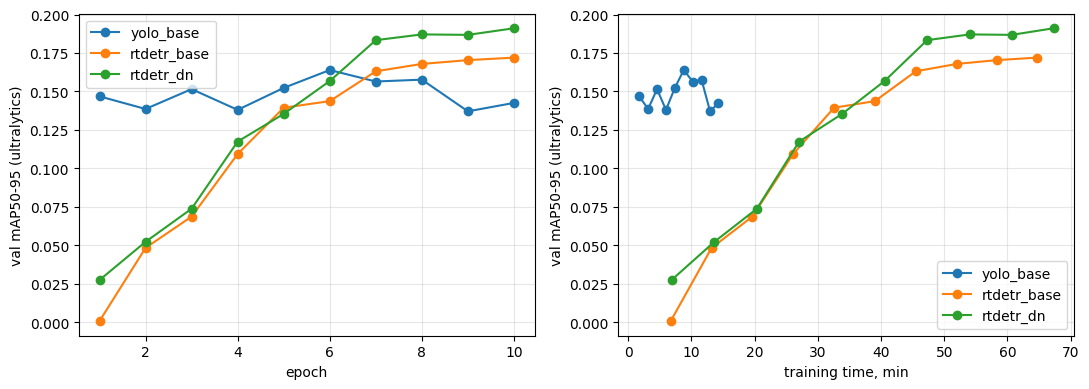

        run  epochs   best  best_epoch   last  gain_last3  train_min            status
  yolo_base      10 0.1639           6 0.1426     -0.0139       14.3 flat or too short
rtdetr_base      10 0.1720          10 0.1720      0.0089       64.6   still improving
  rtdetr_dn      10 0.1911          10 0.1911      0.0077       67.3 flat or too short


In [33]:
CURVES = ["yolo_base", "rtdetr_base", "rtdetr_dn"]       # add more run names to compare (same epoch budget)
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
rows = []
for n in CURVES:
    f = WORK / "runs" / n / "results.csv"
    if not f.exists():
        print(f"{n}: no results.csv in {f.parent}"); continue
    d = pd.read_csv(f); d.columns = [c.strip() for c in d.columns]
    y = d["metrics/mAP50-95(B)"]
    axs[0].plot(d["epoch"], y, marker="o", label=n)
    if "time" in d:
        axs[1].plot(d["time"] / 60, y, marker="o", label=n)
    last = float(y.iloc[-1]); gain = last - float(y.iloc[max(0, len(y) - 4)])
    rows.append({"run": n, "epochs": len(y), "best": round(float(y.max()), 4), "best_epoch": int(d["epoch"][y.idxmax()]),
                 "last": round(last, 4), "gain_last3": round(gain, 4),
                 "train_min": round(float(d["time"].iloc[-1]) / 60, 1) if "time" in d else None,
                 "status": "still improving" if (len(y) >= 4 and gain > 0.05 * last) else "flat or too short"})
axs[0].set_xlabel("epoch"); axs[1].set_xlabel("training time, min")
for a in axs:
    a.set_ylabel("val mAP50-95 (ultralytics)"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()
if rows:
    print(pd.DataFrame(rows).to_string(index=False))


## F3. Error analysis
Detections with score >= 0.3 are matched to ground truth (IoU 0.5, greedy by score). False positives are split into:
- **duplicate**: GT already matched by a better box
- **class**: right place (IoU >= 0.5) but wrong class
- **localisation**: right class, IoU 0.1-0.5
- **background**: IoU < 0.1 with everything

Detections whose centre is inside an ignored region are dropped. Missed GT (false negatives) are counted by object size and by class. Error rate = (false positives + missed GT) / GT in the frame, it can be above 1. The worst frame of each of the three worst *different* videos is drawn (green = TP, red = FP, yellow = missed GT), so the three failure cases do not come from one scene.

In [34]:
def iou_mat(a, b):
    a, b = np.asarray(a, float).reshape(-1, 4), np.asarray(b, float).reshape(-1, 4)
    ix = np.clip(np.minimum(a[:, None, 2], b[None, :, 2]) - np.maximum(a[:, None, 0], b[None, :, 0]), 0, None)
    iy = np.clip(np.minimum(a[:, None, 3], b[None, :, 3]) - np.maximum(a[:, None, 1], b[None, :, 1]), 0, None)
    inter = ix * iy
    ua = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    ub = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (ua[:, None] + ub[None, :] - inter + 1e-9)

def xywh2xyxy(boxes):
    b = np.asarray(boxes, float).reshape(-1, 4).copy()
    b[:, 2:] += b[:, :2]
    return b

def error_analysis(name, thr=0.3, show=3, min_gt=10):
    dets = pickle.load(open(WORK / f"{TAG}dets_{name}.pkl", "rb"))
    fp, fn_size, n_size, fn_cls, n_cls, frames = Counter(), Counter(), Counter(), Counter(), Counter(), []
    for d in dets:
        anns = GT.imgToAnns[d["image_id"]]
        g = [a for a in anns if not a["iscrowd"]]
        cr = xywh2xyxy([a["bbox"] for a in anns if a["iscrowd"]])
        gb, gc = xywh2xyxy([a["bbox"] for a in g]), np.array([a["category_id"] - 1 for a in g])
        k = d["scores"] >= thr
        pb, pc, ps = d["boxes"][k], d["classes"][k], d["scores"][k]
        if len(pb) and len(cr):                      # drop detections inside ignored regions
            cx, cy = (pb[:, 0] + pb[:, 2]) / 2, (pb[:, 1] + pb[:, 3]) / 2
            inside = ((cx[:, None] >= cr[None, :, 0]) & (cx[:, None] <= cr[None, :, 2]) &
                      (cy[:, None] >= cr[None, :, 1]) & (cy[:, None] <= cr[None, :, 3])).any(1)
            pb, pc, ps = pb[~inside], pc[~inside], ps[~inside]
        order = np.argsort(-ps)
        iou = iou_mat(pb, gb) if len(pb) and len(gb) else np.zeros((len(pb), len(gb)))
        matched, labels = np.zeros(len(gb), bool), {}
        for j in order:
            if iou.shape[1] == 0:
                labels[j] = "background"; continue
            same = np.where(gc == pc[j], iou[j], 0)
            t = int(same.argmax())
            if same[t] >= 0.5:
                labels[j] = "duplicate" if matched[t] else "TP"
                matched[t] = True
            elif iou[j].max() >= 0.5:
                labels[j] = "class"
            elif same.max() >= 0.1:
                labels[j] = "localisation"
            else:
                labels[j] = "background"
        for l in labels.values():
            fp[l] += 1
        for t, a in enumerate(g):
            s = math.sqrt(a["bbox"][2] * a["bbox"][3])
            sz = "small" if s < 32 else ("medium" if s < 96 else "large")
            n_size[sz] += 1; n_cls[CLASS_NAMES[gc[t]]] += 1
            if not matched[t]:
                fn_size[sz] += 1; fn_cls[CLASS_NAMES[gc[t]]] += 1
        nerr = sum(l != "TP" for l in labels.values()) + int((~matched).sum())
        if len(g) >= min_gt:
            frames.append((nerr / len(g), d["image_id"], pb, pc, ps, labels, gb, matched))
    tp = fp["TP"]; nfp = sum(v for k, v in fp.items() if k != "TP")
    print(f"{name}: TP {tp} | FP {nfp} -> " + ", ".join(f"{k} {fp[k]}" for k in ["duplicate", "class", "localisation", "background"]))
    print("missed GT by size :", {k: f"{fn_size[k] / n_size[k]:.2f} of {n_size[k]}" for k in ["small", "medium", "large"] if n_size[k]})
    print("missed GT by class:", {k: f"{fn_cls[k] / n_cls[k]:.2f}" for k in CLASS_NAMES if n_cls[k]})
    frames.sort(key=lambda x: -x[0])
    seen, pick = set(), []
    for fr in frames:                                  # the worst frame of each video
        vid = GT.imgs[fr[1]].get("video", fr[1])
        if vid not in seen:
            seen.add(vid); pick.append(fr)
        if len(pick) == show:
            break
    fig, axs = plt.subplots(1, max(1, len(pick)), figsize=(7 * max(1, len(pick)), 4.5))
    for ax, (rate, iid, pb, pc, ps, labels, gb, matched) in zip(np.atleast_1d(axs), pick):
        ax.imshow(Image.open(OUT / "val" / GT.imgs[iid]["file_name"])); ax.axis("off")
        for t in np.where(~matched)[0]:
            x1, y1, x2, y2 = gb[t]; ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="yellow", lw=1))
        for j, l in labels.items():
            x1, y1, x2, y2 = pb[j]
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="lime" if l == "TP" else "red", lw=.8))
        ax.set_title(f"{GT.imgs[iid].get('video', '')} / {GT.imgs[iid]['file_name'].split('/')[-1][:20]} | error rate {rate:.2f}", fontsize=8)
    plt.tight_layout(); plt.show()
    return frames

_ = error_analysis(RUN[0]) if (WORK / f"{TAG}dets_{RUN[0]}.pkl").exists() else None

IndexError: list index out of range

Call `error_analysis('frcnn_base')` etc. for other runs. For the Faster R-CNN failure-case section use the three frames from the picture above (each from a different video) and write the plausible cause yourself (small size, occlusion, ignored region border, class confusion van/car, ...).

## F4. Dense vs sparse frames
Val frames are split into three groups by the number of ground-truth objects; mAP per group. Used to discuss dense scenes (NMS-based vs query-based).

In [ ]:
def density_table(names):
    cnt = {i: sum(1 for a in GT.imgToAnns[i] if not a["iscrowd"]) for i in VAL_IDS}
    s = pd.Series(cnt)
    grp = pd.qcut(s.rank(method="first"), 3, labels=["sparse", "medium", "dense"])
    print("objects per frame:", {g: f"{s[grp == g].min()}-{s[grp == g].max()}" for g in ["sparse", "medium", "dense"]})
    out = {}
    for n in names:
        f = WORK / f"{TAG}dets_{n}.pkl"
        if f.exists():
            dets = pickle.load(open(f, "rb"))
            out[n] = {g: round(coco_eval_from(dets, ids=list(s.index[grp == g]))["mAP"], 4) for g in ["sparse", "medium", "dense"]}
    print(pd.DataFrame(out).T.to_string())

density_table([p.stem[len(f"{TAG}metrics_"):] for p in sorted(WORK.glob(f"{TAG}metrics_*.json"))])

# RT-DETR: number of queries vs objects per frame
_gt_n = pd.Series({i: sum(1 for a in GT.imgToAnns[i] if not a["iscrowd"]) for i in VAL_IDS})
for n in [k for k in VARIANTS if k.startswith("rtdetr")]:
    nq = VARIANTS[n].get("dec", {}).get("num_queries", 300)
    print(f"{n}: {nq} queries | val frames with more GT than queries: {int((_gt_n > nq).sum())} | max GT per val frame {int(_gt_n.max())} (train max 180)")

## Report checklist (write it yourself, in your own words)
| Rubric item | Where in this notebook | What to write |
|---|---|---|
| Data understanding | A: 2.1-2.6, observation table | which observation led to which choice |
| Two-stage | F1 rows `frcnn_*`, `rpn_recall@N`, F3 | what RPN gives (recall) vs second stage (classification, box refinement); 3 failure cases with causes |
| One-stage anchor-based | C2 coverage table, F1 `retina_*` | why default anchors do not fit, what removing the proposal stage costs (fg/bg imbalance, focal loss), compare to tuned Faster R-CNN |
| One-stage anchor-free | F1 `yolo_*` (AP small/medium/large) | how positions get assigned to objects without anchors, effect on small/dense objects, search range |
| Query-based | F2 (curves + convergence table), F4 (density, queries), F1 `rtdetr_*` and the `params` column | bipartite matching vs NMS, effect of queries / denoising / matching cost, convergence in the epoch budget, small/dense behaviour |
| Your pipeline | the best run + submission | justify from the earlier tables, run instructions, seed |

Limitations to mention honestly: one split (given by the organisers), single seed, speed measured with batch 4 (Ultralytics) vs batch 1 (torchvision), unequal augmentation between torchvision and Ultralytics models, val resolution differs from test.